
# Patient Triage from Free-Text Complaints — Russian and Kazakh

The goal of this project is not diagnosis, but **safe routing**: from the text of a patient's complaint, decide

1. the **urgency** of the case (`routine` / `urgent` / `emergency`),
2. if it is not an emergency — **which specialist** to route to (`терапевт`, `кардиолог`, `невролог`, `гастроэнтеролог`, `дерматолог`, `ЛОР`),
3. **which entities** the decision rests on — the symptom, the body site, how long it has lasted,
4. and now also **which language** the complaint is written in.

```
Complaint text
      ↓
Language identification  (ru / kk / mixed)
      ↓
NER layer, routed by language → symptom, body site, duration, negation
      ↓
Urgency check (ML + red-flag rules, in both languages)
      ↓
Any emergency signs?
      ├── Yes → "ambulance / emergency care", no specialist assigned
      └── No → specialist classifier → therapist as the safe fallback
```

**What changed in this version.** Patients in Kazakhstan write in Russian, in Kazakh, and in both at once inside one sentence. The dataset, the NER layer and the red-flag rules now cover all three cases, and the evaluation was rebuilt around a proper **train / validation / test** protocol: every threshold and model choice is now made on validation data, and the test set is read once, at the end.

**Important note.** This is an educational prototype on a self-built dataset. Complaint texts, symptom names and specialist labels stay in **Russian and Kazakh** on purpose — that is the language the system is meant to work in, and translating them would break the character-level processing used throughout. The Kazakh portion was written for this project and has not been reviewed by a native-speaker clinician.


## 1. Imports and data

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, recall_score, f1_score)

# Russian-language NLP stack
import pymorphy3
from razdel import tokenize
from natasha import Segmenter, NewsEmbedding, NewsNERTagger, Doc

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)

In [2]:
pool = pd.read_csv("triage_dataset.csv")      # everything the project may learn from
external = pd.read_csv("triage_holdout.csv")  # written separately, in other words

print("labelled pool:", pool.shape, "| external holdout:", external.shape)
print()
print("rows by language and urgency:")
print(pool.groupby(["lang", "urgency"]).size().unstack(fill_value=0).to_string())
print()
print("where the rows come from:")
print(pool["source"].value_counts().to_string())
print()
print("no complaint is shared between the two files:",
      len(set(pool["text"]) & set(external["text"])) == 0)
pool.sample(8, random_state=5)[["text", "urgency", "specialist", "lang"]]

labelled pool: (6387, 6) | external holdout: (682, 6)

rows by language and urgency:
urgency  emergency  routine  urgent
lang                               
kk             145      467     455
mixed           39       88     198
ru             569     2315    2111

where the rows come from:
source
template_generated_paraphrased    4415
kk_generated                      1067
original                           500
mixed_generated                    325
manual_diverse                      80

no complaint is shared between the two files: True


,text,urgency,specialist,lang
1468,"Здравствуйте, доктор, Покраснение и зуд между пальцами ног. Заранее спасибо за ответ.",routine,дерматолог,ru
3233,"добрый день, температура скачет то 37, то 38 который день несколько дней сегодня утром. буду благодарен за совет",urgent,терапевт,ru
5201,"Амансыз ба, ұйқы режимі туралы сұрағым бар Не істеу керек?",routine,невролог,kk
3504,"Здравствуйте, Бессонница уже месяц, не могу уснуть пару часов назад.",urgent,невролог,ru
6209,"сыпь на коже, тырнақтарым сынғыш болып кетті",urgent,дерматолог,mixed
3672,"Добрый день, Боль в груди отдает в челюсть, тяжело дышать, началось резко. Что делать в такой ситуации?",emergency,скорая помощь,ru
5835,спортқа рұқсат қағазы керек кешеден бері,routine,терапевт,kk
758,"Скажите, пожалуйста, Не может говорить внятно, слова путаются, началось только что.",emergency,скорая помощь,ru


## 2. Exploratory data analysis

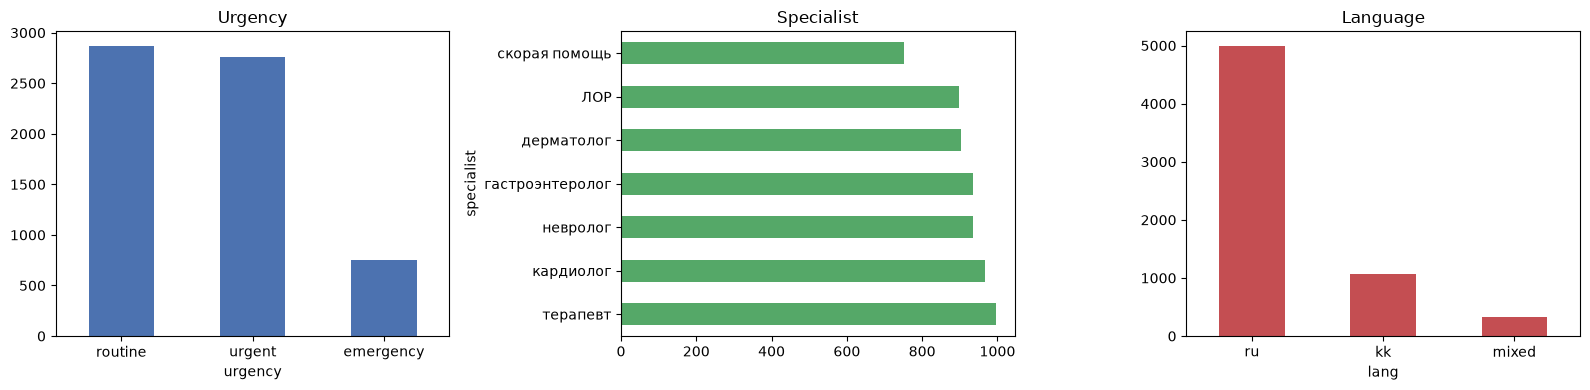

        count  mean  min   max
lang                          
kk     1067.0   8.0  2.0  17.0
mixed   325.0   9.4  3.0  17.0
ru     4995.0  12.9  3.0  29.0


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

pool["urgency"].value_counts().reindex(["routine", "urgent", "emergency"]).plot(
    kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Urgency")
axes[0].tick_params(axis="x", rotation=0)

pool["specialist"].value_counts().plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Specialist")

pool["lang"].value_counts().plot(kind="bar", ax=axes[2], color="#C44E52")
axes[2].set_title("Language")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

pool["n_words"] = pool["text"].str.split().str.len()
print(pool.groupby("lang")["n_words"].describe()[["count", "mean", "min", "max"]].round(1).to_string())

## 3. Text preprocessing

The cleaner lowercases the complaint and drops everything that is not a letter, a digit or basic punctuation. One detail in that sentence decides whether Kazakh works at all.

The earlier version kept the range `а-яё`. That range **does not contain the nine letters Kazakh adds to Cyrillic** — `ә ғ қ ң ө ұ ү һ і` — so a complaint like `«құлағым ауырады»` was silently reduced to `«ла ым ауырады»` before any model saw it. The character class below keeps them.

In [4]:
KK_EXTRA = "әғқңөұүһі"

def clean_text(t: str) -> str:
    t = str(t).lower()
    t = re.sub(f"[^а-яё{KK_EXTRA}0-9\\s.,]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

# what the old Russian-only class did to a Kazakh complaint
def clean_text_ru_only(t: str) -> str:
    t = re.sub(r"[^а-яё0-9\s.,]", " ", str(t).lower())
    return re.sub(r"\s+", " ", t).strip()

demo = "Құлағым ауырады, қызуым жоқ"
print("raw          :", demo)
print("old cleaner  :", clean_text_ru_only(demo))
print("fixed cleaner:", clean_text(demo))

pool["text_clean"] = pool["text"].apply(clean_text)
external["text_clean"] = external["text"].apply(clean_text)

raw          : Құлағым ауырады, қызуым жоқ
old cleaner  : ла ым ауырады, ызуым жо
fixed cleaner: құлағым ауырады, қызуым жоқ


## 4. The evaluation protocol: train / validation / test

This section is the answer to the main methodological problem of the previous version: **there was no validation set.** Model choice, the vectorizer and the confidence threshold were all compared on the same data that was then reported as the result, which makes every reported number optimistic by an unknown amount — the test set had effectively been used for tuning.

The pool is therefore split three ways, and each part has exactly one job:

| Split | Share | What it is allowed to do |
|---|---|---|
| **train** | 70% | fit model parameters |
| **validation** | 15% | every decision: vectorizer, classifier, confidence threshold |
| **test** | 15% | read **once**, at the very end, and never used to choose anything |

On top of that sits `triage_holdout.csv`, an **external** set written separately, describing the same clinical situations in deliberately different vocabulary. Test and external holdout answer different questions: test says how well the system does on complaints phrased like its training data; the external set says what happens when a patient writes in their own words.

The split is stratified on urgency **and** language together, so each part keeps the same class and language mix — otherwise the rarer `mixed` rows would clump into one split by chance.

In [5]:
strat = pool["urgency"] + "|" + pool["lang"]

train_df, temp_df = train_test_split(
    pool, test_size=0.30, stratify=strat, random_state=RANDOM_STATE)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50,
    stratify=temp_df["urgency"] + "|" + temp_df["lang"], random_state=RANDOM_STATE)

for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:>11}: {len(part):>5} rows")
print(f"{'external':>11}: {len(external):>5} rows (separate file, different wording)")
print()

shares = pd.DataFrame({
    name: part["urgency"].value_counts(normalize=True)
    for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]
}).round(3)
print("urgency shares are preserved across splits:")
print(shares.to_string())

# TEST_UNLOCKED stays False until section 11. Any accidental use of the test
# split before then is meant to be visible rather than silent.
TEST_UNLOCKED = False

      train:  4470 rows
 validation:   958 rows
       test:   959 rows
   external:   682 rows (separate file, different wording)

urgency shares are preserved across splits:
           train  validation   test
urgency                            
routine    0.449       0.449  0.449
urgent     0.433       0.433  0.433
emergency  0.118       0.118  0.118


## 5. Language identification

Before anything else can be routed, the system has to know what it is reading. Two approaches are compared, and the comparison is decided on **validation**.

**The rule.** Kazakh Cyrillic adds nine letters Russian does not have, so any word carrying one is unambiguously Kazakh. A short marker-word list votes for the words that carry none.

**The learned model.** Character n-grams over single words, trained on the monolingual rows of the *training split only*, then applied word by word.

The interesting case is the third class. A code-switched complaint such as `«қызуым бар, давление скачет»` contains a Russian fragment whose letters all exist in Kazakh too — so the rule has nothing to fire on and reads the sentence as pure Kazakh.

In [6]:
WORD_RE = re.compile(f"[а-яё{KK_EXTRA}]+")
KK_LETTERS = set(KK_EXTRA)
RU_ONLY_LETTERS = set("эъёщц")
KK_MARKERS = {"мен", "бар", "жоқ", "керек", "деп", "ма", "ме", "бе", "ба",
              "және", "осы", "ол", "бұл", "не", "да", "де"}
RU_MARKERS = {"и", "в", "на", "не", "что", "как", "уже", "очень", "болит",
              "боль", "день", "дня", "второй", "третий", "нет", "есть", "меня",
              "по", "за", "мне", "это", "спасибо", "здравствуйте", "подскажите",
              "пожалуйста", "доктор", "неделю", "месяц", "сильно", "после"}


def detect_language_rule(text):
    """Letter-and-marker rule — no training data involved."""
    words = WORD_RE.findall(str(text).lower())
    if not words:
        return "ru"
    kk = ru = 0
    for w in words:
        chars = set(w)
        if chars & KK_LETTERS:
            kk += 1
        elif chars & RU_ONLY_LETTERS or w in RU_MARKERS:
            ru += 1
        elif w in KK_MARKERS:
            kk += 1
    if kk + ru == 0:
        return "ru"
    share = kk / (kk + ru)
    return "kk" if share >= 0.8 else ("ru" if share <= 0.2 else "mixed")

In [7]:
MIN_LEN = 3      # shorter tokens carry almost no orthographic signal
CONF = 0.65      # a word counts as evidence only above this probability

def words_of(text):
    return [w for w in WORD_RE.findall(str(text).lower()) if len(w) >= MIN_LEN]

# trained on TRAIN only — the validation and test rows must stay unseen
ru_words, kk_words = [], []
for text, lang in zip(train_df["text"], train_df["lang"]):
    if lang == "ru":
        ru_words += words_of(text)
    elif lang == "kk":
        kk_words += words_of(text)

ru_set, kk_set = set(ru_words), set(kk_words)
AMBIGUOUS = ru_set & kk_set          # spellings that exist in both languages
vocab = sorted(ru_set | kk_set)
X_lid = [w for w in vocab if w not in AMBIGUOUS]
y_lid = ["ru" if w in ru_set else "kk" for w in X_lid]

word_lid = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(1, 3), min_df=1)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
]).fit(X_lid, y_lid)

_kk_i = list(word_lid.classes_).index("kk")
_ru_i = list(word_lid.classes_).index("ru")


# "mixed" is the only class that needs evidence of BOTH languages, so it is the
# only one a short sentence can reach by accident: four ordinary words carrying
# little orthographic signal were enough to tip plain Russian into it. The two
# thresholds below say how much evidence the claim costs.
MIN_MINORITY = 2      # confident words of the weaker language
MIN_EVIDENCE = 5      # confident words in the sentence overall


def detect_language(text):
    """Learned detector: classify each word, then judge the sentence by the mix."""
    ws = [w for w in words_of(text) if w not in AMBIGUOUS]
    if not ws:
        return "ru"
    probs = word_lid.predict_proba(ws)
    kk = sum(1 for p in probs if p[_kk_i] >= CONF)
    ru = sum(1 for p in probs if p[_ru_i] >= CONF)
    if kk + ru == 0:
        return "ru"
    share = kk / (kk + ru)
    majority = "kk" if share >= 0.5 else "ru"
    if share >= 0.85:
        return "kk"
    if share <= 0.15:
        return "ru"
    # between the two thresholds: only call it mixed if the claim is paid for
    if kk + ru < MIN_EVIDENCE or min(kk, ru) < MIN_MINORITY:
        return majority
    return "mixed"

print(f"training words: {len(X_lid)} | spellings shared by both languages: {len(AMBIGUOUS)}")


# The reported label and the routing decision have different cost structures, so
# they are no longer the same call. Sending a Russian complaint through the
# Kazakh extractor as well costs nothing — the extra extractor simply finds
# nothing. Sending a genuinely bilingual complaint through only one extractor
# silently drops half its entities. Routing therefore errs towards running both.
ROUTE_MINORITY = 1     # a single confident word of the other language is enough


def extraction_langs(text):
    """Which extractors to run — deliberately more inclusive than the label."""
    ws = [w for w in words_of(text) if w not in AMBIGUOUS]
    if not ws:
        return ("ru",)
    probs = word_lid.predict_proba(ws)
    kk = sum(1 for p in probs if p[_kk_i] >= CONF)
    ru = sum(1 for p in probs if p[_ru_i] >= CONF)
    if min(kk, ru) >= ROUTE_MINORITY:
        return ("ru", "kk")
    return ("kk",) if kk > ru else ("ru",)

training words: 1803 | spellings shared by both languages: 2


In [8]:
rows = []
for name, fn in [("rule", detect_language_rule), ("learned", detect_language)]:
    pred = [fn(t) for t in val_df["text"]]
    rows.append({
        "detector": name,
        "accuracy": round((np.array(pred) == val_df["lang"].values).mean(), 3),
        "recall kk": round(recall_score(val_df["lang"], pred, labels=["kk"], average="macro"), 3),
        "recall mixed": round(recall_score(val_df["lang"], pred, labels=["mixed"], average="macro"), 3),
        "recall ru": round(recall_score(val_df["lang"], pred, labels=["ru"], average="macro"), 3),
    })
print("measured on VALIDATION:")
print(pd.DataFrame(rows).set_index("detector").to_string())
print()
print("learned detector, validation:")
print(classification_report(val_df["lang"], [detect_language(t) for t in val_df["text"]],
                            digits=3, zero_division=0))

measured on VALIDATION:
          accuracy  recall kk  recall mixed  recall ru
detector                                              
rule         0.969      0.988         0.429        1.0
learned      0.991      1.000         0.816        1.0

learned detector, validation:


              precision    recall  f1-score   support

          kk      0.947     1.000     0.973       160
       mixed      1.000     0.816     0.899        49
          ru      1.000     1.000     1.000       749

    accuracy                          0.991       958
   macro avg      0.982     0.939     0.957       958
weighted avg      0.991     0.991     0.990       958



**Result.** Both detectors separate Russian from Kazakh almost perfectly — that part of the task is decided by nine letters and needs no model. They part company on `mixed`, where the rule's recall collapses while the learned detector keeps it high.

The reason is worth stating precisely, because it is the whole argument for the learned approach: the rule can only recognise a language by evidence *for* it, and a Russian fragment made of letters that Kazakh also uses provides none. Character n-grams instead learn what Russian and Kazakh **spelling** looks like — which letter sequences occur, in which order — so a word like `давление` is recognisably Russian without containing a single Russian-only letter.

The learned detector is used from here on.

## 6. The NER layer, in two languages

The classifier treats a complaint as one undivided blob of characters. This layer pulls the facts out of it — *what* hurts, *where*, *for how long*, and what the patient explicitly denies — so the system can show the grounds for its decision instead of only a label.

The two languages need genuinely different machinery, and the reason is linguistic rather than practical:

| | Russian | Kazakh |
|---|---|---|
| tokenizer | `razdel` | the same regex over the extended alphabet |
| word normalisation | `pymorphy3` — a real dictionary morphology over OpenCorpora | **does not exist** at that quality |
| how the dictionary matches | by lemma: one entry `боль` covers `болит`, `болью`, `болел` | by **stem plus a recognised suffix** |
| name removal | `natasha` (Slovnet), a neural NER trained on news | not covered |

Kazakh is agglutinative: `құлақ` ("ear") becomes `құлағым`, `құлағымда`, `құлағынан`. With no analyser to reduce those to one lemma, the layer matches a stem and checks that what follows is a known suffix. Two things had to be handled before that worked:

- **a free remainder matches nonsense.** Allowing any ending turns `жөтелім басылмай` ("the cough will not settle") into the body part `бас` ("head"), because the word begins with those three letters. The remainder must be an actual suffix.
- **the final consonant changes.** `қ`, `к` and `п` voice before a vowel ending: `тамақ` + `ым` = `тамағ`+`ым`. Every stem therefore also needs its voiced form, or `тамағым` ("my throat") is never found.

A small stop-list handles the remaining collisions — without it the very common intensifier `қатты` ("very") is read as the symptom stem `қат-` ("constipation").

In [9]:
_morph = pymorphy3.MorphAnalyzer()
_segmenter = Segmenter()
_ner_tagger = NewsNERTagger(NewsEmbedding())

# lemma -> canonical symptom name
SYMPTOM_LEMMAS = {
    "боль": "боль", "болеть": "боль", "ныть": "ноющая боль",
    "раскалываться": "боль", "щемить": "щемящая боль", "простреливать": "прострел",
    "температура": "температура", "жар": "температура", "лихорадка": "температура",
    "знобить": "озноб", "озноб": "озноб",
    "тошнить": "тошнота", "тошнота": "тошнота", "рвота": "рвота", "рвать": "рвота",
    "кружиться": "головокружение", "головокружение": "головокружение",
    "слабость": "слабость", "усталость": "слабость", "утомляемость": "слабость",
    "одышка": "одышка", "задыхаться": "одышка", "дышать": "нарушение дыхания",
    "хрипеть": "хрипы", "свистеть": "свистящее дыхание",
    "кашель": "кашель", "кашлять": "кашель", "насморк": "насморк",
    "сыпь": "сыпь", "высыпание": "сыпь", "крапивница": "сыпь",
    "покраснение": "покраснение", "пятно": "пятно", "родинка": "родинка",
    "зуд": "зуд", "чесаться": "зуд", "жечь": "жжение", "жжение": "жжение",
    "печь": "жжение", "изжога": "изжога", "вздутие": "вздутие",
    "тяжесть": "тяжесть", "покалывание": "покалывание", "колоть": "покалывание",
    "неметь": "онемение", "онеметь": "онемение", "онемение": "онемение",
    "перекосить": "асимметрия лица", "кровотечение": "кровотечение", "кровь": "кровь",
    "давление": "давление", "пульс": "пульс", "сердцебиение": "сердцебиение",
    "отёк": "отёк", "опухнуть": "отёк", "судорога": "судороги",
    "бессонница": "бессонница", "уснуть": "нарушение сна", "мигрень": "мигрень",
    "аппетит": "изменение аппетита", "глотать": "нарушение глотания",
    "голос": "изменение голоса", "зрение": "нарушение зрения",
    "сознание": "потеря сознания", "обморок": "обморок",
    "стул": "нарушение стула", "понос": "диарея", "запор": "запор",
    "синеть": "цианоз", "посинеть": "цианоз", "подавиться": "инородное тело",
    # mined from unmatched frequent words in the TRAINING split (section 6c)
    "простуда": "простуда", "больно": "боль", "тянуть": "ноющая боль",
    "заложить": "заложенность", "спать": "нарушение сна", "гастрит": "гастрит",
    "скакать": "колебания давления", "отдавать": "иррадиация",
    "ожог": "ожог", "волдырь": "волдыри", "потливость": "потливость",
    "потеть": "потливость", "мёрзнуть": "зябкость", "ангина": "ангина",
    "гипертония": "гипертония", "пробка": "пробки в миндалинах",
    "укус": "укус", "травма": "травма", "перелом": "перелом",
}

# lemma -> canonical body location
LOCATION_LEMMAS = {
    "голова": "голова", "головной": "голова", "висок": "висок",
    "горло": "горло", "глотка": "горло", "ухо": "ухо", "уха": "ухо",
    "нос": "нос", "глаз": "глаз", "зуб": "зуб", "десна": "десна",
    "живот": "живот", "желудок": "желудок", "кишечник": "кишечник",
    "грудь": "грудная клетка", "грудина": "грудная клетка", "сердце": "сердце",
    "спина": "спина", "поясница": "поясница", "шея": "шея",
    "нога": "нога", "колено": "колено", "стопа": "стопа",
    "рука": "рука", "плечо": "плечо", "палец": "палец", "кисть": "кисть",
    "кожа": "кожа", "лицо": "лицо", "ноготь": "ноготь",
    "печень": "печень", "почка": "почка", "лёгкое": "лёгкие", "бок": "бок",
    "сустав": "сустав", "мышца": "мышца", "язык": "язык", "речь": "речь",
    "тело": "тело", "ребро": "ребро", "губа": "губы", "локоть": "локоть",
}

# Negation. Russian puts it on either side of the word: "не болит" but also
# "температуры нет", so both directions are checked.
NEG_BEFORE = {"не", "без", "ни"}
NEG_AFTER = {"нет"}
NEG_WINDOW_BEFORE = 2
# "температуры ВРОДЕ нет": a hedging particle can sit between the symptom and
# its negation. Only these words may intervene — allowing any token would make
# "голова болит, тошноты нет" negate the headache.
NEG_PARTICLES = {"вроде", "пока", "уже", "совсем", "особо", "сильно",
                 "больше", "как", "то", "бы", "же", "видимо", "кажется"}

# "без сознания" is the symptom itself, not its absence. Without this exception
# the layer reads a red-flag complaint as "no loss of consciousness" — the single
# most dangerous mistake this code could make.
NEGATION_EXCEPTIONS = {("без", "сознание"), ("без", "сила"), ("без", "воздух")}

# duration
_NUMERAL_LEMMAS = {
    "один": 1, "два": 2, "две": 2, "три": 3, "четыре": 4, "пять": 5,
    "шесть": 6, "семь": 7, "восемь": 8, "девять": 9, "десять": 10,
    "первый": 1, "второй": 2, "третий": 3, "четвёртый": 4, "пятый": 5,
    "шестой": 6, "седьмой": 7, "пара": 3, "несколько": 3,
}
_UNIT_TO_DAYS = {
    "минута": 1 / 1440, "час": 1 / 24, "день": 1, "сутки": 1,
    "неделя": 7, "месяц": 30, "полгода": 180, "год": 365,
}
_VAGUE_DURATION = {"вчера": 1, "позавчера": 2, "давно": 90, "хронический": 90}

print(f"Symptom dictionary: {len(SYMPTOM_LEMMAS)} lemmas -> "
      f"{len(set(SYMPTOM_LEMMAS.values()))} canonical symptoms")
print(f"Location dictionary: {len(LOCATION_LEMMAS)} lemmas -> "
      f"{len(set(LOCATION_LEMMAS.values()))} canonical locations")

Symptom dictionary: 90 lemmas -> 64 canonical symptoms
Location dictionary: 42 lemmas -> 38 canonical locations


In [10]:
# A stem fallback for words the dictionary cannot reduce ("головушка" -> "голова").
# One stem can open several dictionary words ("голов" -> "голова" and also
# "головокружение"), so candidates are kept together and the one closest in
# length to the word being resolved wins.
def _build_stems():
    stems = {}
    for table, kind in ((SYMPTOM_LEMMAS, "symptom"), (LOCATION_LEMMAS, "location")):
        for key, value in table.items():
            if len(key) >= 6:
                stems.setdefault(key[:5], []).append((key, value, kind))
    return stems

_STEMS = _build_stems()


def _lemmas_of(word):
    """Every lemma pymorphy proposes, not just the top-scoring one.

    For "онемела" the best parse is the adjective "онемелый"; the verb "онеметь"
    we actually need sits second with an identical score, so taking parse()[0]
    silently loses the symptom.
    """
    return {p.normal_form for p in _morph.parse(word)}


def _analyze(text):
    tokens = [t for t in tokenize(text.lower()) if t.text.isalpha() or t.text.isdigit()]
    return [(t.text, _lemmas_of(t.text)) for t in tokens]


def _match_word(lemmas):
    """Exact dictionary hit wins; the stem fallback only runs if nothing matched."""
    for lemma in lemmas:
        if lemma in SYMPTOM_LEMMAS:
            return SYMPTOM_LEMMAS[lemma], None
        if lemma in LOCATION_LEMMAS:
            return None, LOCATION_LEMMAS[lemma]
    for lemma in lemmas:
        if len(lemma) < 6 or lemma[:5] not in _STEMS:
            continue
        _key, value, kind = min(_STEMS[lemma[:5]],
                                key=lambda c: abs(len(c[0]) - len(lemma)))
        return (value, None) if kind == "symptom" else (None, value)
    return None, None


# Real clinical notes write durations in forms the token walk below never sees:
# "в течение 3- х месяцев", "последних 3-х дней", "1,5 месяца". A regex pass over
# the raw string catches those before the token walk runs. Derived from the
# TRAIN portion of the real-complaint corpus only (section 16).
_DUR_RAW = re.compile(
    r"(\d+(?:[.,]\d+)?)\s*-?\s*[хйеx]?\s*"
    r"(дн|ден|дней|сут|недел|нед|месяц|мес|год|лет|час)", re.IGNORECASE)
_DUR_RAW_UNITS = {"дн": 1, "ден": 1, "дней": 1, "сут": 1, "недел": 7, "нед": 7,
                  "месяц": 30, "мес": 30, "год": 365, "лет": 365, "час": 1 / 24}


def extract_duration_raw(text):
    m = _DUR_RAW.search(str(text))
    if not m:
        return None, None
    num = float(m.group(1).replace(",", "."))
    return m.group(0).strip(), round(num * _DUR_RAW_UNITS[m.group(2).lower()], 2)


def extract_duration(analyzed):
    """Return (surface form, approximate length in days) or (None, None)."""
    words = [w for w, _ in analyzed]
    for i, (word, lemmas) in enumerate(analyzed):
        unit = next((u for u in lemmas if u in _UNIT_TO_DAYS), None)
        if unit is None:
            continue
        if unit == "полгода":
            return word, 180
        for back in (1, 2):
            if i - back < 0:
                break
            prev_word, prev_lemmas = analyzed[i - back]
            if prev_word.isdigit():
                return f"{prev_word} {word}", round(int(prev_word) * _UNIT_TO_DAYS[unit], 2)
            num = next((_NUMERAL_LEMMAS[l] for l in prev_lemmas if l in _NUMERAL_LEMMAS), None)
            if num is not None:
                return f"{prev_word} {word}", round(num * _UNIT_TO_DAYS[unit], 2)
    for word, lemmas in analyzed:
        hit = next((l for l in lemmas if l in _VAGUE_DURATION), None)
        if hit:
            return word, _VAGUE_DURATION[hit]
    if "со" in words and "вчерашнего" in words:
        return "со вчерашнего дня", 1
    return None, None


_NAME_GRAMMEMES = {"Name", "Surn", "Patr"}


def _looks_like_a_name(fragment):
    """Does the morphological dictionary actually know this as a personal name?

    Slovnet was trained on news, where a capitalised word opening a sentence is
    usually somebody's name. In a complaint it is just the first word: without
    this guard "Давящая боль за грудиной" is de-identified into "[ИМЯ] боль за
    грудиной" and the symptom is destroyed. pymorphy has the Name/Surn/Patr
    grammemes for real names, so it acts as the veto.
    """
    return any(_NAME_GRAMMEMES & set(p.tag.grammemes)
               for word in fragment.split()
               for p in _morph.parse(word.strip(".,!?")))


def anonymize(text):
    """Remove person names using Natasha's neural NER, vetoed by pymorphy."""
    doc = Doc(text)
    doc.segment(_segmenter)
    doc.tag_ner(_ner_tagger)
    out, shift = text, 0
    for span in doc.spans:
        if span.type == "PER" and _looks_like_a_name(text[span.start:span.stop]):
            start, stop = span.start + shift, span.stop + shift
            out = out[:start] + "[ИМЯ]" + out[stop:]
            shift += len("[ИМЯ]") - (span.stop - span.start)
    return out


def _negated_after(analyzed, i):
    """A postposed "нет", optionally behind one or two hedging particles."""
    for step in (1, 2, 3):
        j = i + step
        if j >= len(analyzed):
            return False
        lemmas = analyzed[j][1]
        if NEG_AFTER & lemmas:
            return True
        if not (lemmas & NEG_PARTICLES):
            return False
    return False


def extract_entities(text):
    """Symptoms, body locations, duration and explicitly denied symptoms."""
    analyzed = _analyze(text)
    symptoms, locations, negated = [], [], []

    for i, (_word, lemmas) in enumerate(analyzed):
        before = [l for _w, ls in analyzed[max(0, i - NEG_WINDOW_BEFORE):i] for l in ls]
        is_negated = bool(NEG_BEFORE & set(before)) or _negated_after(analyzed, i)
        if is_negated and any((neg, lemma) in NEGATION_EXCEPTIONS
                              for neg in before for lemma in lemmas):
            is_negated = False

        symptom, location = _match_word(lemmas)
        if symptom:
            target = negated if is_negated else symptoms
            if symptom not in target:
                target.append(symptom)
        if location and location not in locations:
            locations.append(location)

    duration_text, duration_days = extract_duration(analyzed)
    if duration_text is None:
        duration_text, duration_days = extract_duration_raw(text)
    return {
        "symptoms": symptoms,
        "locations": locations,
        "negated": negated,
        "duration_text": duration_text,
        "duration_days": duration_days,
    }

The Kazakh side: stems, suffixes and the multi-word patterns that no single stem can carry.

In [11]:
KK_SUFFIXES = {
    "", "ы", "і", "ым", "ім", "м", "ың", "ің", "ңыз", "ңіз", "сы", "сі",
    "ға", "ге", "қа", "ке", "на", "не", "а", "е",
    "да", "де", "та", "те", "нда", "нде", "ында", "інде",
    "дан", "ден", "тан", "тен", "нан", "нен", "ынан", "інен",
    "ды", "ді", "ты", "ті", "ны", "ні", "ын", "ін",
    "ына", "іне", "ыма", "іме", "ымда", "імде", "ымды", "імді", "ымның", "імнің",
    "мен", "бен", "пен", "лар", "лер", "дар", "дер", "тар", "тер",
    "ады", "еді", "айды", "ейді", "ып", "іп", "п", "ды", "ған", "ген", "қан", "кен",
    "мда", "мде", "мнан", "мнен", "иды", "иді", "ыс", "іс", "у", "у керек",
}

# Frequent Kazakh words that merely start like a medical stem. Without this list
# the intensifier "қатты" ("very") is read as the symptom "қат-" (constipation).
KK_STOPWORDS = {
    "қатты", "қалды", "қалай", "қай", "қайда", "қашан", "қажет", "қарату",
    "жатыр", "келді", "келеді", "керек", "кейін", "деп", "бері", "болады",
    "бар", "жоқ", "емес", "сонымен", "басқа", "бастап", "басылмай",
    "денсаулық", "дәрігер", "дәрі", "күн", "күні", "кеше", "бүгін",
}

KK_LOCATION_STEMS = {
    "бас": "голова", "шеке": "висок", "желке": "затылок",
    "тамақ": "горло", "жұтқыншақ": "горло", "бадамша": "миндалины",
    "құлақ": "ухо", "мұрын": "нос", "мұрн": "нос", "танау": "нос",
    "көз": "глаз", "тіс": "зуб", "бет": "лицо", "дауыс": "голос",
    "іш": "живот", "асқазан": "желудок", "бауыр": "печень",
    "кеуде": "грудная клетка", "жүрек": "сердце", "қабырға": "ребро",
    "арқа": "спина", "мойын": "шея", "мойн": "шея", "бел": "поясница",
    "аяқ": "нога", "қол": "рука", "саусақ": "палец", "білек": "предплечье",
    "тері": "кожа", "тырнақ": "ноготь", "шаш": "волосы", "буын": "сустав",
    "тамыр": "пульс", "ерн": "губы", "ерін": "губы",
}

KK_SYMPTOM_STEMS = {
    "ауыр": "боль", "ауырсын": "боль", "сыз": "ноющая боль", "сырқыра": "ноющая боль",
    "шанш": "покалывание", "қыш": "зуд", "ісі": "отёк",
    "қызу": "температура", "ыстық": "температура", "температура": "температура",
    "қалтыра": "озноб", "тоң": "озноб",
    "жөтел": "кашель", "түшкір": "чихание", "тұмаурат": "простуда",
    "әлсіз": "слабость", "дәрменсіз": "слабость", "шарша": "слабость",
    "айнал": "головокружение", "зең": "головокружение",
    "лоқсы": "тошнота", "құсу": "рвота", "кекір": "отрыжка", "кеб": "вздутие",
    "тәбет": "изменение аппетита", "бөртпе": "сыпь", "безеу": "сыпь",
    "дақ": "пятно", "қызар": "покраснение", "мең": "родинка",
    "қабыршақтан": "шелушение", "құрға": "сухость",
    "қан": "кровь", "қысым": "давление", "соғ": "сердцебиение",
    "ұйы": "онемение", "тұншық": "удушье", "тыныс": "нарушение дыхания",
    "талма": "судороги", "құрыс": "судороги", "тартыл": "судороги",
    "ұйықта": "нарушение сна", "ұйқысыздық": "бессонница",
    "күй": "ожог", "жара": "рана", "улан": "отравление", "у": "отравление",
    "бұлдыра": "нарушение зрения", "қарлық": "изменение голоса",
    "бітел": "заложенность", "шуыл": "шум в ушах", "бұра": "спазм",
    "бозар": "бледность", "көгер": "цианоз", "сіңб": "нарушение пищеварения",
}

# Multi-word states no single stem can carry. Each word may itself be inflected
# ("ішім өтіп" for "іш өт-"), so these are regexes, not literal substrings.
KK_PHRASES = {
    r"ес\w*\s+тан": "потеря сознания",
    r"өзіне\s+кел": "потеря сознания",
    r"дем\w*\s+ала\s+алма": "удушье",
    r"тыныс\w*\s+ала\s+алма": "удушье",
    r"тұншы\w*": "удушье",
    r"қан\w*\s+тоқтама": "кровотечение",
    r"қан\w*\s+тый": "кровотечение",
    r"қан\w*\s+кет": "кровотечение",
    r"сөз\w*\s+күрмел": "нарушение речи",
    r"сөйлей\s+алма": "нарушение речи",
    r"бет\w*\s+қисай": "асимметрия лица",
    r"ес\w*\s+кіресілі": "нарушение сознания",
    r"іш\w*\s+өт": "диарея",
    r"іш\w*\s+қат": "запор",
    r"нашар\s+ест": "нарушение слуха",
}
_KK_PHRASE_RES = None  # compiled lazily below

KK_NEGATION = {"жоқ", "емес"}

_KK_NUM = {"бір": 1, "екі": 2, "үш": 3, "төрт": 4, "бес": 5,
           "екінші": 2, "үшінші": 3, "төртінші": 4, "бесінші": 5}
_KK_UNIT_DAYS = {"сағат": 1 / 24, "күн": 1, "апта": 7, "ай": 30, "жыл": 365}

_ALT = {"қ": "ғ", "к": "г", "п": "б"}


def _variants(stem):
    """The stem plus its voiced form, for қ/к/п before a vowel suffix."""
    out = {stem}
    if stem and stem[-1] in _ALT:
        out.add(stem[:-1] + _ALT[stem[-1]])
    return out


def _expand(table):
    out = {}
    for stem, value in table.items():
        for v in _variants(stem):
            out[v] = value
    return out


_LOC = _expand(KK_LOCATION_STEMS)
_SYM = _expand(KK_SYMPTOM_STEMS)
_KK_PHRASE_RES = [(re.compile(p), v) for p, v in KK_PHRASES.items()]


def _kk_match(word, table):
    """Longest stem the word starts with, when the remainder is a known suffix."""
    if word in KK_STOPWORDS:
        return None
    best = None
    for stem, value in table.items():
        if word.startswith(stem) and word[len(stem):] in KK_SUFFIXES:
            if best is None or len(stem) > len(best[0]):
                best = (stem, value)
    return best[1] if best else None


def kk_duration(text):
    low = str(text).lower()
    m = re.search(r"(\d+)\s*(күн|сағат|апта|ай|жыл)", low)
    if m:
        return m.group(0), round(int(m.group(1)) * _KK_UNIT_DAYS[m.group(2)], 2)
    m = re.search(r"(бір|екі|үш|төрт|бес|екінші|үшінші|төртінші|бесінші)\s*"
                  r"(күн|апта|ай|жыл)", low)
    if m:
        return m.group(0), round(_KK_NUM[m.group(1)] * _KK_UNIT_DAYS[m.group(2)], 2)
    m = re.search(r"(кешеден|түннен|бүгін таңертең|көптен|ай бойы|жарты жыл\w*)", low)
    if m:
        return m.group(0), 1 if m.group(1) in ("кешеден", "түннен") else 90
    return None, None


def kk_entities(text):
    low = str(text).lower()
    words = WORD_RE.findall(low)
    symptoms, locations, negated = [], [], []

    for rx, value in _KK_PHRASE_RES:
        if rx.search(low) and value not in symptoms:
            symptoms.append(value)

    for i, w in enumerate(words):
        nxt = words[i + 1] if i + 1 < len(words) else ""
        is_neg = nxt in KK_NEGATION
        s = _kk_match(w, _SYM)
        if s:
            tgt = negated if is_neg else symptoms
            if s not in tgt and s not in negated:
                tgt.append(s)
        loc = _kk_match(w, _LOC)
        if loc and loc not in locations:
            locations.append(loc)

    d_text, d_days = kk_duration(low)
    return {"symptoms": symptoms, "locations": locations, "negated": negated,
            "duration_text": d_text, "duration_days": d_days}

Both sides are now put behind one function. The language detector decides which one runs, and a `mixed` complaint is passed through **both** — a code-switched sentence genuinely contains entities of each language, and dropping either half loses real information.

In [12]:
def extract_entities_any(text):
    """Entities from a complaint in Russian, Kazakh, or both at once."""
    langs = extraction_langs(text)
    parts = []
    if "ru" in langs:
        parts.append(extract_entities(text))
    if "kk" in langs:
        parts.append(kk_entities(text))

    out = {"symptoms": [], "locations": [], "negated": [],
           "duration_text": None, "duration_days": None}
    for p in parts:
        for field in ("symptoms", "locations", "negated"):
            for v in p[field]:
                if v not in out[field]:
                    out[field].append(v)
        if out["duration_text"] is None and p["duration_text"]:
            out["duration_text"] = p["duration_text"]
            out["duration_days"] = p["duration_days"]
    # a symptom explicitly denied anywhere is not a symptom
    out["symptoms"] = [s for s in out["symptoms"] if s not in out["negated"]]
    out["lang"] = detect_language(text)
    out["extractors"] = langs
    return out


examples = [
    "Здравствуйте! У меня третий день болит голова и тошнит, температуры нет.",
    "Давящая боль за грудиной, отдаёт в левую руку",
    "Сәлеметсіз бе, екінші күн басым қатты ауырады, қызуым жоқ",
    "құлағым ауырады үш күннен бері, нашар естимін",
    "Сәлеметсіз бе, қызуым бар, кашель не проходит уже неделю",
    "хочу пройти обычный профилактический осмотр",
]
for raw in examples:
    e = extract_entities_any(raw)
    facts = {k: v for k, v in e.items()
             if k not in ("lang", "extractors") and v}
    print(f"[{e['lang']:>5}] extractors={'+'.join(e['extractors'])}  {raw}")
    print("        ", facts if facts else "no entities (no complaint in the text)")
    print()

[   ru] extractors=ru  Здравствуйте! У меня третий день болит голова и тошнит, температуры нет.
         {'symptoms': ['боль', 'тошнота'], 'locations': ['голова'], 'negated': ['температура'], 'duration_text': 'третий день', 'duration_days': 3}

[   ru] extractors=ru  Давящая боль за грудиной, отдаёт в левую руку
         {'symptoms': ['боль', 'иррадиация'], 'locations': ['грудная клетка', 'рука']}

[   kk] extractors=kk  Сәлеметсіз бе, екінші күн басым қатты ауырады, қызуым жоқ
         {'symptoms': ['боль'], 'locations': ['голова'], 'negated': ['температура'], 'duration_text': 'екінші күн', 'duration_days': 2}

[   kk] extractors=kk  құлағым ауырады үш күннен бері, нашар естимін
         {'symptoms': ['нарушение слуха', 'боль'], 'locations': ['ухо'], 'duration_text': 'үш күн', 'duration_days': 3}

[mixed] extractors=ru+kk  Сәлеметсіз бе, қызуым бар, кашель не проходит уже неделю
         {'symptoms': ['кашель', 'температура']}

[   ru] extractors=ru  хочу пройти обычный профилактическ

In [13]:
def entity_coverage(frame, name):
    parsed = [extract_entities_any(t) for t in frame["text"]]
    out = {"split": name, "n": len(frame)}
    for lang in ["ru", "kk", "mixed"]:
        sel = [p for p, l in zip(parsed, frame["lang"]) if l == lang]
        out[lang] = round(sum(1 for p in sel if p["symptoms"] or p["locations"])
                          / len(sel) * 100, 1) if sel else float("nan")
    emer = [p for p, u in zip(parsed, frame["urgency"]) if u == "emergency"]
    out["emergency only"] = round(sum(1 for p in emer if p["symptoms"] or p["locations"])
                                  / len(emer) * 100, 1)
    return out

coverage = pd.DataFrame([
    entity_coverage(val_df, "validation"),
    entity_coverage(external, "external holdout"),
]).set_index("split")
print("share of complaints where at least one entity was found, %")
coverage

share of complaints where at least one entity was found, %


,n,ru,kk,mixed,emergency only
split,,,,,
validation,958,90.3,67.5,89.8,92.0
external holdout,682,82.2,82.1,86.7,85.3


**Coverage is not accuracy, and the next section is about how far apart they are.** The table says in what share of complaints the layer found *at least one* entity. It says nothing about whether it found *everything that was there*, and nothing about whether what it found was right. A layer that spots one symptom out of three in every complaint scores 100% here.

Reported alone, this number would be the most flattering thing in the notebook. Section 6b measures the quantity it is standing in for.

## 6b. Measuring the NER layer against a hand-annotated gold standard

Up to now the layer was judged by coverage. That is a proxy, and this section is what the proxy was hiding.

Sixty complaints were drawn from the **external holdout** and annotated by hand: every symptom, every body site, and whether a duration is stated. The annotation rule is the part that makes the number meaningful — **the gold records what a reader finds in the text, not what the dictionaries happen to contain**. Annotating against the dictionary would have the layer grade its own homework, and every score would come out near 1.0.

Entities the system currently cannot produce are therefore present in the gold on purpose. `тремор`, `выпадение волос`, `паралич`, `утопление` are all in there. They are what the recall figure is for.

In [14]:
# (text, symptoms, locations, has_duration)
GOLD = [
    # ---------------------------------------------------------------- Russian
    ("на солнцепёке потерял сознание, весь красный и горячий.",
     ["потеря сознания", "покраснение", "температура"], [], False),
    ("Разрешите обратиться, Давление в пазухах и боль при наклоне головы. Подскажите, куда лучше обратиться.",
     ["давление", "боль"], ["нос", "голова"], False),
    ("Жжёт за грудиной после плотного ужина.",
     ["жжение"], ["грудная клетка"], False),
    ("пучит и урчит без остановки после обеда. Насколько это серьёзно?",
     ["вздутие"], [], False),
    ("Приветствую, Губы синеют, воздуха не хватает совсем. Подскажите, что делать до приезда врачей.",
     ["цианоз", "удушье"], ["губы"], False),
    ("боль под рёбрами справа после жирного шашлыка.",
     ["боль"], ["ребро"], False),
    ("Прошу прощения за вопрос, Виски сдавливает будто обручем к вечеру. Подскажите, куда лучше обратиться.",
     ["боль"], ["висок"], False),
    ("пальцы подрагивают, когда волнуюсь на совещаниях",
     ["тремор"], ["палец"], False),
    ("Хотела бы спросить, Тошнит и слабость валит с ног второй день с позавчерашнего дня. Что скажете?",
     ["тошнота", "слабость"], [], True),
    ("Прошу прощения за вопрос, Голова раскалывается, обезболивающее не берёт уже которые сутки. Подскажите, куда лучше обратиться.",
     ["боль"], ["голова"], True),
    ("Приветствую, Сердце трепещет, как будто птица бьётся в клетке буквально с полчаса.",
     ["сердцебиение"], ["сердце"], True),
    ("чужая собака цапнула глубоко, кровь не унимается с самого утра. Скорую уже вызвали.",
     ["укус", "кровотечение"], [], True),
    ("ошпарился кипятком, кожа пузырится и жутко болит около месяца точно. Скорую уже вызвали.",
     ["ожог", "волдыри", "боль"], ["кожа"], True),
    ("Волосы лезут клоками при расчёсывании с позавчерашнего дня. Волнуюсь за это.",
     ["выпадение волос"], ["волосы"], True),
    ("добрый день, доктор, ногти крошатся и слоятся последнее время с позавчерашнего дня. очень жду совета",
     ["ломкость ногтей"], ["ноготь"], True),
    ("Разрешите обратиться, Кожа зимой шелушится и стягивает так, что больно улыбаться. Подскажите, куда лучше обратиться.",
     ["шелушение", "сухость", "боль"], ["кожа"], False),
    ("Прошу прощения за вопрос, Локти сухие и трескаются.",
     ["сухость"], ["локоть"], False),
    ("Уши звенят после громкого концерта. Может, само пройдёт?",
     ["шум в ушах"], ["ухо"], False),
    ("голос сел напрочь, шепчу вместо разговора с самого утра",
     ["изменение голоса"], ["голос"], True),
    ("Прошу прощения за вопрос, Нос забит с утра до вечера каждый день уже которые сутки. Может, само пройдёт?",
     ["заложенность"], ["нос"], True),
    ("Разрешите обратиться, Горло дерёт, глотать неприятно, температуры вроде нет. Подскажите, куда лучше обратиться.",
     ["боль", "нарушение глотания"], ["горло"], False),
    ("аппетит пропал напрочь, тяжесть весь день не отпускает с позавчерашнего дня.",
     ["изменение аппетита", "тяжесть"], [], True),
    ("Разрешите обратиться, Живот крутит после каждой чашки кофе. Может, само пройдёт?",
     ["спазм"], ["живот"], False),
    ("Добрый день, доктор, Боль под рёбрами справа после жирного шашлыка.",
     ["боль"], ["ребро"], False),
    ("Разрешите обратиться, Губы синеют, воздуха не хватает совсем которую неделю уже. Скорую уже вызвали.",
     ["цианоз", "удушье"], ["губы"], True),
    ("Приветствую, Спину обсыпало угрями уже которые сутки. Раньше подобного не замечала.",
     ["сыпь"], ["спина"], True),

    # ---------------------------------------------------------------- Kazakh
    ("еңбекке жарамдылық қағазы керек қайда баруым керек?", [], [], False),
    ("Кешірерсіз, үш аптадан бері теріні қарату керек пе деп едім Кеңесіңіз қажет",
     [], ["кожа"], True),
    ("денесі тартылып, құрысып қалды Тезірек!", ["судороги"], ["тело"], False),
    ("екі күннен бері ас мәзірі бойынша кеңес керек", [], [], True),
    ("улы зат жұтып қойған сияқты Не істерімізді білмей тұрмыз", ["отравление"], [], False),
    ("Ассалаумағалейкум, үш аптадан бері кеудем қысылады Жауап берсеңіз",
     ["сдавление"], ["грудная клетка"], True),
    ("Сәлем, білегім қышып, тырналып қалды ай бойы", ["зуд"], ["предплечье"], True),
    ("Кешірерсіз, тамыр соғысын өлшетсем деп едім", [], ["пульс"], False),
    ("аяғым ұйиды Кеңесіңіз қажет", ["онемение"], ["нога"], False),
    ("Сәлем, еңбекке жарамдылық қағазы керек", [], [], False),
    ("отқа күйіп, терісі сыдырылды", ["ожог"], ["кожа"], False),
    ("Сәлем, терім құрғап кетті үш аптадан бері Көмектессеңіз", ["сухость"], ["кожа"], True),
    ("Қайырлы таң, екі күннен бері дауысым шықпай қалды", ["изменение голоса"], ["голос"], True),
    ("Кешірерсіз, дем ала алмай қалды Жедел көмек керек!", ["удушье"], [], False),
    ("отқа күйіп, терісі сыдырылды Тезірек!", ["ожог"], ["кожа"], False),
    ("асқазаным ашиды", ["изжога"], ["желудок"], False),
    ("Қайырлы таң, жұтқыншағым ауырсынады Жауап берсеңіз", ["боль"], ["горло"], False),
    ("Ассалаумағалейкум, сөзі күрмеліп, бір жағы қимылдамайды",
     ["нарушение речи", "паралич"], [], False),
    ("жөтелден тынышым кетті", ["кашель"], [], False),
    ("баласы суға батып қалды Жедел көмек керек!", ["утопление"], [], False),

    # ---------------------------------------------------------------- mixed
    ("Сұрағым бар еді, құлақты қарату керек пе деп сұрайын дедім, плановая проверка слуха төртінші күн Көмектессеңіз",
     [], ["ухо"], True),
    ("түннен бері вопрос по диете, ас мәзірі бойынша кеңес керек", [], [], True),
    ("жөтелден тынышым кетті, знобит весь день", ["кашель", "озноб"], [], False),
    ("Сәлем, знобит весь день, жөтелден тынышым кетті Жауап берсеңіз",
     ["кашель", "озноб"], [], False),
    ("Кешірерсіз, тамақ сіңбейді, мутит после еды Жауап берсеңіз",
     ["нарушение пищеварения", "тошнота"], [], False),
    ("ыстығым бар, знобит весь день", ["температура", "озноб"], [], False),
    ("желкем ауырады, виски ломит", ["боль"], ["затылок", "висок"], False),
    ("Сәлем, нужно пройти медосмотр, медициналық тексеруден өтсем деп едім", [], [], False),
    ("Сұрағым бар еді, пульс частит, жүрек соғысы жиілеп кетті Кеңесіңіз қажет",
     ["сердцебиение"], ["пульс", "сердце"], False),
    ("медициналық тексеруден өтсем деп едім, нужно пройти медосмотр", [], [], False),
    ("Ассалаумағалейкум, кровь хлещет, баласы суға батып қалды",
     ["кровотечение", "утопление"], [], False),
    # "хочу проверить давление" is a request, not a reported symptom — the
    # dictionary fires on the word anyway, which is what makes this row useful
    ("тамыр соғысын өлшетсем деп едім, хочу проверить давление төртінші күн",
     [], ["пульс"], True),
    ("Кешірерсіз, упал и не встаёт, дем ала алмай қалды", ["удушье", "падение"], [], False),
    ("ас мәзірі бойынша кеңес керек, вопрос по диете төртінші күн", [], [], True),
]

# The two halves of the layer were built separately and name a few concepts
# differently. Collapsing those pairs keeps the score about extraction rather
# than about vocabulary bookkeeping.
NORM = {
    "нарушение дыхания": "удушье",
    "кровь": "кровотечение",
    "обморок": "потеря сознания",
    "нарушение сна": "бессонница",
    "ноющая боль": "боль",
    "щемящая боль": "боль",
}


def norm(items):
    return {NORM.get(x, x) for x in items}


def score(gold_sets, pred_sets):
    """Micro precision / recall / F1 over a list of (gold, predicted) sets."""
    tp = sum(len(g & p) for g, p in zip(gold_sets, pred_sets))
    fp = sum(len(p - g) for g, p in zip(gold_sets, pred_sets))
    fn = sum(len(g - p) for g, p in zip(gold_sets, pred_sets))
    prec = tp / (tp + fp) if tp + fp else float("nan")
    rec = tp / (tp + fn) if tp + fn else float("nan")
    f1 = 2 * prec * rec / (prec + rec) if tp else 0.0
    return {"tp": tp, "fp": fp, "fn": fn,
            "precision": round(prec, 3), "recall": round(rec, 3), "f1": round(f1, 3)}


langs_gold = ["ru"] * 26 + ["kk"] * 20 + ["mixed"] * 14

gs_all, ps_all, gl_all, pl_all = [], [], [], []
dur_ok = lang_ok = 0
disagreements = []

for (text, g_sym, g_loc, g_dur), lang in zip(GOLD, langs_gold):
    e = extract_entities_any(text)
    gs, ps = norm(g_sym), norm(e["symptoms"])
    gl, pl = norm(g_loc), norm(e["locations"])
    gs_all.append(gs); ps_all.append(ps)
    gl_all.append(gl); pl_all.append(pl)
    dur_ok += int(bool(e["duration_text"]) == g_dur)
    lang_ok += int(e["lang"] == lang)
    if gs ^ ps:
        disagreements.append((lang, text[:60], sorted(gs - ps), sorted(ps - gs)))

overall = pd.DataFrame([
    dict(entity="symptoms", **score(gs_all, ps_all)),
    dict(entity="locations", **score(gl_all, pl_all)),
]).set_index("entity")
print("NER measured against the gold standard (60 complaints):")
print(overall.to_string())
print()
print(f"duration present/absent, accuracy: {dur_ok}/{len(GOLD)} = {dur_ok/len(GOLD):.3f}")
print(f"language label, accuracy:          {lang_ok}/{len(GOLD)} = {lang_ok/len(GOLD):.3f}")
print()

per_lang = []
for lang in ["ru", "kk", "mixed"]:
    idx = [i for i, l in enumerate(langs_gold) if l == lang]
    per_lang.append(dict(lang=lang, entity="symptoms",
                         **score([gs_all[i] for i in idx], [ps_all[i] for i in idx])))
    per_lang.append(dict(lang=lang, entity="locations",
                         **score([gl_all[i] for i in idx], [pl_all[i] for i in idx])))
pd.DataFrame(per_lang).set_index(["lang", "entity"])

NER measured against the gold standard (60 complaints):
           tp  fp  fn  precision  recall     f1
entity                                         
symptoms   37   2  32      0.949   0.536  0.685
locations  35   2   5      0.946   0.875  0.909

duration present/absent, accuracy: 49/60 = 0.817
language label, accuracy:          58/60 = 0.967



tp  fp  fn  precision  recall     f1
lang  entity                                         
ru    symptoms   18   0  21      1.000   0.462  0.632
      locations  19   1   3      0.950   0.864  0.905
kk    symptoms    9   0   7      1.000   0.562  0.720
      locations  11   0   1      1.000   0.917  0.957
mixed symptoms   10   2   4      0.833   0.714  0.769
      locations   5   1   1      0.833   0.833  0.833

In [15]:
print(f"complaints where the symptom sets disagree: {len(disagreements)} of {len(GOLD)}\n")
for lang, text, missed, spurious in disagreements[:18]:
    print(f"[{lang:>5}] {text}")
    if missed:
        print(f"         missed:   {missed}")
    if spurious:
        print(f"         spurious: {spurious}")

complaints where the symptom sets disagree: 30 of 60

[   ru] на солнцепёке потерял сознание, весь красный и горячий.
         missed:   ['покраснение', 'температура']
[   ru] пучит и урчит без остановки после обеда. Насколько это серьё
         missed:   ['вздутие']
[   ru] Приветствую, Губы синеют, воздуха не хватает совсем. Подскаж
         missed:   ['удушье']
[   ru] Прошу прощения за вопрос, Виски сдавливает будто обручем к в
         missed:   ['боль']
[   ru] пальцы подрагивают, когда волнуюсь на совещаниях
         missed:   ['тремор']
[   ru] Приветствую, Сердце трепещет, как будто птица бьётся в клетк
         missed:   ['сердцебиение']
[   ru] чужая собака цапнула глубоко, кровь не унимается с самого ут
         missed:   ['укус']
[   ru] ошпарился кипятком, кожа пузырится и жутко болит около месяц
         missed:   ['волдыри', 'ожог']
[   ru] Волосы лезут клоками при расчёсывании с позавчерашнего дня. 
         missed:   ['выпадение волос']
[   ru] добрый день, доктор, но

**The result, and it is not a comfortable one.** Precision is high and recall is about half: the layer is right about what it reports and silent about much of what is there. Coverage said 75-86%; the quantity coverage was standing in for is a good deal lower.

Locations do considerably better than symptoms, and the reason is structural rather than linguistic: the body has a few dozen names and they recur, while a symptom can be phrased a hundred ways — `пучит`, `крутит`, `дерёт`, `сдавливает`, `трепещет` are all ordinary Russian for conditions the dictionary holds under other words.

Worth noting which language does better. Russian symptom recall is **lower** than Kazakh, despite Russian having a real morphological analyser behind it. That is not a statement about the languages. The external holdout was written to use vocabulary the training data does not, and the Russian half of it exercises that much harder — which is exactly what section 6a shows cannot be fixed by mining the training split.

The few false positives are each worth a sentence, because they are different kinds of error:

- `хочу проверить давление` — the word `давление` is present, but as a **request**, not a reported symptom. Telling those apart is assertion detection, which this layer does not attempt.
- `пульс частит` — the layer reports `пульс` as a body site and misses `сердцебиение`, so it is half right in a way the scorer counts as both a miss and a false positive.

## 6c. Why the obvious fix does not work

Recall of about one half is a dictionary problem, and the obvious response is to make the dictionary bigger. The question is where the new entries are allowed to come from.

Reading them off the gold set would be the end of the measurement: the layer would be tuned on its own evaluation and the next F1 would mean nothing. The legitimate source is the **training split**, which the project is free to inspect. That was done — the frequent word forms it never matches were extracted, and the genuinely medical ones among them (`простуда`, `больно`, `заложить`, `тянуть`, `спать`, `гастрит`, `скакать`, `отдавать`, plus the body sites `тело`, `ребро`, `губы`, `локоть`) were added.

The effect was lopsided, and the cell below says why.

In [16]:
missed_words = [
    # surface forms behind the gold misses in section 6b
    "пучит", "трепещет", "цапнула", "ошпарился", "пузырится", "шелушится",
    "звенят", "крутит", "обсыпало", "дерёт", "сдавливает", "подрагивают",
    "крошатся", "слоятся", "лезут",
]

train_vocab = set()
for t in train_df["text"]:
    train_vocab.update(WORD_RE.findall(str(t).lower()))

present = [w for w in missed_words if w in train_vocab]
absent = [w for w in missed_words if w not in train_vocab]

print(f"training vocabulary: {len(train_vocab)} distinct word forms")
print()
print(f"of the {len(missed_words)} words behind the gold misses,")
print(f"  {len(present)} occur anywhere in the training split: {present}")
print(f"  {len(absent)} do not: {absent}")
print()

ext_vocab = set()
for t in external["text"]:
    ext_vocab.update(WORD_RE.findall(str(t).lower()))
unseen = ext_vocab - train_vocab
print(f"external holdout vocabulary: {len(ext_vocab)} forms, "
      f"of which {len(unseen)} ({len(unseen)/len(ext_vocab):.0%}) never appear in training")

training vocabulary: 1841 distinct word forms

of the 15 words behind the gold misses,
  0 occur anywhere in the training split: []
  15 do not: ['пучит', 'трепещет', 'цапнула', 'ошпарился', 'пузырится', 'шелушится', 'звенят', 'крутит', 'обсыпало', 'дерёт', 'сдавливает', 'подрагивают', 'крошатся', 'слоятся', 'лезут']

external holdout vocabulary: 766 forms, of which 401 (52%) never appear in training


**That is the ceiling, stated numerically.** Most of the words the layer failed on are not in the training split at all — which is not a flaw in the mining, it is the external holdout doing its job. It was written to use different vocabulary, so the words that expose the dictionary are precisely the words no amount of careful reading of the training data could have produced.

Two consequences follow, and both shaped the rest of this notebook:

- Locations improved substantially from mining (recall 0.75 → 0.875) and symptoms barely moved (0.52 → 0.54). Body sites are a closed list of a few dozen words that recur everywhere; symptom phrasings are open-ended.
- A hand-written dictionary cannot be fixed into generality by looking harder at data you already have. Either it grows from an external medical lexicon, or the matching stops being lexical. Section 12 tests the second option.

## 7. Choosing the vectorizer — decided on validation

Text has to become numbers, and how it does decides what the model can see. Two options, fitted on **train** and compared on **validation**:

- **word n-grams** — features are whole words and pairs. `болит` and `болел` are unrelated features, and `құлағым` and `құлақ` are too.
- **character n-grams** (`char_wb`, 3–5) — features are letter sequences inside word boundaries, so inflected forms of one word share most of their features.

Both measure surface form, not meaning. Neither knows that `жжёт в груди` and `кеудем ашиды` describe the same thing; that would need multilingual embeddings.

In [17]:
def fit_eval(vec, est, X_tr, y_tr, X_va, y_va):
    pipe = Pipeline([("tfidf", vec), ("clf", est)]).fit(X_tr, y_tr)
    return round(f1_score(y_va, pipe.predict(X_va), average="macro"), 3)

VECTORIZERS = {
    "word (1-2)": lambda: TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=1),
    "char_wb (3-5)": lambda: TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1),
}

tr_spec = train_df[train_df["urgency"] != "emergency"]
va_spec = val_df[val_df["urgency"] != "emergency"]

rows = []
for name, make_vec in VECTORIZERS.items():
    rows.append({
        "vectorizer": name,
        "urgency f1": fit_eval(make_vec(),
                               LogisticRegression(max_iter=2000, class_weight="balanced"),
                               train_df["text_clean"], train_df["urgency"],
                               val_df["text_clean"], val_df["urgency"]),
        "specialist f1": fit_eval(make_vec(), LinearSVC(C=1.0, class_weight="balanced"),
                                  tr_spec["text_clean"], tr_spec["specialist"],
                                  va_spec["text_clean"], va_spec["specialist"]),
    })
print("f1_macro on VALIDATION (fitted on train):")
pd.DataFrame(rows).set_index("vectorizer")

f1_macro on VALIDATION (fitted on train):


,urgency f1,specialist f1
vectorizer,,
word (1-2),0.985,0.968
char_wb (3-5),0.982,0.982


**Result, and it is not the one the earlier version assumed.** On urgency the two vectorizers are a tie — the difference is smaller than the noise between splits, and nothing would justify preferring one. On the specialist task character n-grams win clearly.

That split makes sense. Urgency is signalled by whole blunt words that appear in one form (`скорая`, `судороги`, `профилактика`), so word features already capture it. Picking the right specialist out of six depends on one precise medical noun, and that noun appears inflected: `изжога / изжогу / изжоги`, `құлақ / құлағым / құлағымда`. Word features scatter those across separate columns; character fragments hold them together.

`char_wb (3-5)` is used for both models from here on — it wins where the decision is hard and ties where it is easy. Note also *where* this was decided: on validation, with the test split untouched.

## 8. Part A — the urgency model

TF-IDF on character n-grams plus logistic regression with `class_weight="balanced"`, so the rarer `emergency` class is not drowned out by the two common ones.

The regularisation strength `C` is selected on validation, by the metric that actually matters here. `f1_macro` treats all three classes alike, but the three errors are not alike: routing an `urgent` case as `routine` costs a delay, while missing an `emergency` can cost a life. Selection therefore maximises **recall on `emergency`**, with `f1_macro` reported alongside to show what that costs.

In [18]:
def make_urgency(C):
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1)),
        ("clf", LogisticRegression(C=C, max_iter=2000, class_weight="balanced")),
    ])

rows = []
for C in [0.5, 1.0, 2.0, 5.0, 10.0]:
    pipe = make_urgency(C).fit(train_df["text_clean"], train_df["urgency"])
    pred = pipe.predict(val_df["text_clean"])
    rows.append({
        "C": C,
        "recall emergency": round(recall_score(val_df["urgency"], pred,
                                               labels=["emergency"], average="macro"), 3),
        "f1_macro": round(f1_score(val_df["urgency"], pred, average="macro"), 3),
    })
search = pd.DataFrame(rows).set_index("C")
print("urgency model selection, measured on VALIDATION:")
print(search.to_string())

BEST_C = float(search["recall emergency"].idxmax())
print(f"\nselected C = {BEST_C} (highest recall on emergency)")

urgency_pipeline = make_urgency(BEST_C).fit(train_df["text_clean"], train_df["urgency"])

urgency model selection, measured on VALIDATION:
      recall emergency  f1_macro
C                               
0.5              0.965     0.973
1.0              0.973     0.982
2.0              0.982     0.988
5.0              0.982     0.990
10.0             0.982     0.991

selected C = 2.0 (highest recall on emergency)


urgency, VALIDATION:
              precision    recall  f1-score   support

   emergency      1.000     0.982     0.991       113
     routine      0.982     0.993     0.987       430
      urgent      0.988     0.981     0.984       415

    accuracy                          0.986       958
   macro avg      0.990     0.985     0.988       958
weighted avg      0.986     0.986     0.986       958



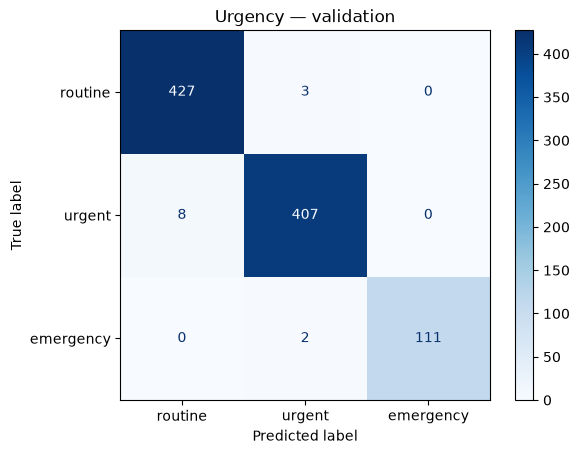

In [19]:
val_pred = urgency_pipeline.predict(val_df["text_clean"])
print("urgency, VALIDATION:")
print(classification_report(val_df["urgency"], val_pred, digits=3))

labels = ["routine", "urgent", "emergency"]
cm = confusion_matrix(val_df["urgency"], val_pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title("Urgency — validation")
plt.show()

## 9. Part B — the specialist model

Fitted only on non-emergency rows: an emergency gets an ambulance, not a specialist appointment.

Two things are chosen here on validation. The first is `C` for the linear SVM. The second is the **confidence threshold** — the margin between the top two classes below which the system stops guessing and routes to a therapist instead. In the previous version that threshold was a hard-coded `0.15` with a comment admitting it was picked by eye; it is now selected against what it is actually for: raising the accuracy of the answers the system does commit to, while leaving the fallback rate reasonable.

In [20]:
rows = []
for C in [0.1, 0.5, 1.0, 2.0, 5.0]:
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1)),
        ("clf", LinearSVC(C=C, class_weight="balanced")),
    ]).fit(tr_spec["text_clean"], tr_spec["specialist"])
    rows.append({"C": C, "f1_macro": round(
        f1_score(va_spec["specialist"], pipe.predict(va_spec["text_clean"]),
                 average="macro"), 3)})
spec_search = pd.DataFrame(rows).set_index("C")
print("specialist model selection, measured on VALIDATION:")
print(spec_search.to_string())

BEST_C_SPEC = float(spec_search["f1_macro"].idxmax())
print(f"\nselected C = {BEST_C_SPEC}")

specialist_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1)),
    ("clf", LinearSVC(C=BEST_C_SPEC, class_weight="balanced")),
]).fit(tr_spec["text_clean"], tr_spec["specialist"])

specialist model selection, measured on VALIDATION:
     f1_macro
C            
0.1     0.981
0.5     0.983
1.0     0.982
2.0     0.982
5.0     0.983

selected C = 0.5


In [21]:
def margin_of(texts):
    """Gap between the best and the second-best class — how sure the model is."""
    dec = specialist_pipeline.decision_function(texts)
    top2 = np.sort(dec, axis=1)[:, -2:]
    return top2[:, 1] - top2[:, 0]

va_margin = margin_of(va_spec["text_clean"])
va_pred_spec = specialist_pipeline.predict(va_spec["text_clean"])
va_true_spec = va_spec["specialist"].values

rows = []
for thr in [0.0, 0.1, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0]:
    confident = va_margin > thr
    kept = confident.sum()
    acc = (va_pred_spec[confident] == va_true_spec[confident]).mean() if kept else float("nan")
    rows.append({
        "threshold": thr,
        "answers given %": round(kept / len(va_margin) * 100, 1),
        "accuracy when answering": round(acc, 3),
        "sent to therapist %": round((1 - kept / len(va_margin)) * 100, 1),
    })
thr_table = pd.DataFrame(rows).set_index("threshold")
print("confidence threshold, measured on VALIDATION:")
print(thr_table.to_string())

# keep the highest accuracy available while still answering at least 85% of cases
ok = thr_table[thr_table["answers given %"] >= 85]
CONF_THRESHOLD = float(ok["accuracy when answering"].idxmax())
print(f"\nselected threshold = {CONF_THRESHOLD}"
      f" (best accuracy among thresholds that still answer ≥85% of complaints)")

confidence threshold, measured on VALIDATION:
           answers given %  accuracy when answering  sent to therapist %
threshold                                                               
0.00                 100.0                    0.982                  0.0
0.10                  99.3                    0.987                  0.7
0.25                  98.3                    0.992                  1.7
0.50                  96.0                    0.999                  4.0
1.00                  91.2                    1.000                  8.8
1.50                  69.1                    1.000                 30.9
2.00                  36.3                    1.000                 63.7
3.00                   0.8                    1.000                 99.2

selected threshold = 1.0 (best accuracy among thresholds that still answer ≥85% of complaints)


**What the threshold table shows.** Raising the bar does buy accuracy, but it buys it by refusing to answer — every point of accuracy is paid for in complaints pushed to a therapist. That trade-off is a product decision, not a metric to maximise blindly, so the rule stated above fixes one side of it (answer at least 85% of complaints) and optimises the other. The point of the table is that the number is now *chosen against evidence*, on data that is not the test set.

## 10. Red-flag rules as a safety layer

A short list of phrases that must never be missed. The rules may only ever **raise** urgency to `emergency`, never lower it: a false alarm costs an unnecessary ambulance call, a miss can cost a life, and the two are not worth trading against each other.

The list now has a Kazakh half. Russian entries are matched as plain substrings; Kazakh ones are regexes, because the words inside a phrase inflect too — `есінен танып қалды` and `есінен танды` are the same red flag.

The rules are then measured **on their own**, apart from the model, which is the only way to see what they actually contribute.

In [22]:
# Both halves are now regexes over inflectable stems. The Russian list used to
# be fixed substrings, so "боль за грудиной" matched and "острая боль в груди"
# did not — measured on the training split, that one difference accounted for
# most of the misses.
RED_FLAGS_RU = [
    # breathing
    r"не\s+дыш", r"переста\w*\s+дыш", r"не\s+мог\w*\s+(вдохн|дыш)",
    r"(тяжело|трудно|тяжко)\s+дыш", r"задыха", r"воздух\w*\s+не\s+хвата",
    r"дыхани\w*\s+(останов|пропа)",
    # consciousness and neurology
    r"потер\w*\s+сознани", r"без\s+сознани", r"не\s+приход\w*\s+в\s+себя",
    r"сознани\w*\s+(спута|пута)", r"судорог", r"перекос\w*\s+лиц",
    r"немее\w*\s+(рук|ног|лиц)", r"потер\w*\s+зрени",
    r"не\s+(может|могу)\s+говор", r"слова\s+пута", r"речь\s+пропа",
    r"переста\w*\s+чувствова\w*\s+(прав|лев)", r"инсульт",
    # chest
    r"бол\w*\s+за\s+грудин", r"(остр\w*|резк\w*|давящ\w*|сильн\w*)\s+бол\w*\s+в\s+груд",
    r"бол\w*\s+в\s+груд\w*\s+отда", r"отда\w*\s+в\s+(лев\w*\s+)?(рук|челюст)",
    r"инфаркт",
    # bleeding
    r"кровотечени", r"кров\w*\s+(хлещ|не\s+останавл|не\s+унима)",
    r"сильно\s+кровит", r"потер\w*\s+(много\s+)?кров", r"рвот\w*\s+с\s+кровь",
    # skin / circulation
    r"посине", r"синею", r"губ\w*\s+(синею|посине)", r"побледне", r"бледн\w*\s+как",
    # poisoning, trauma, allergy
    r"(выпил|вып\w*|съел)\w*\s+(слишком\s+)?много\s+таблет", r"отрави",
    r"ударил\w*\s+голов", r"удар\w*\s+в\s+голов",
    r"отека\w*\s+лиц", r"аллергическ\w*\s+реакц",
    r"живот\s+(твёрд|тверд)", r"не\s+может\s+разогн",
    r"наглота\w*\s+воды", r"откача",
]

RED_FLAGS_KK = [
    # breathing
    r"тыныс\w*\s+ала\s+алма", r"дем\w*\s+ала\s+алма", r"дем\s+ала\s+алма",
    r"тұншы\w*", r"тыныс\w*\s+тарыл",
    # consciousness and neurology
    r"ес\w*\s+тан", r"өзіне\s+келме", r"ес\w*\s+ауыс", r"ес\w*\s+кіресілі",
    r"талма", r"құрыс\w*\s+қал", r"денесі\s+тартыл",
    r"бет\w*\s+қисай", r"сөйлей\s+алма", r"сөз\w*\s+күрмел",
    r"инсульт", r"бір\s+жағы\s+(қозғалма|қимылда)",
    # chest
    r"кеуде\w*\s+қатты\s+ауыр", r"жүрек\s+ұстама",
    # bleeding
    r"қан\w*\s+тоқтама", r"қан\w*\s+тый", r"қан\w*\s+кет", r"қан\s+құс",
    # skin / circulation
    r"көгер", r"бозарып\s+кет", r"талықс",
    # poisoning, trauma
    r"у\s+іш", r"улы\s+зат", r"көп\s+дәрі", r"қатты\s+күй",
    r"жұтып\s+қой", r"биіктен\s+құла", r"суға\s+бат", r"соққыдан\s+кейін",
]

_RU_FLAG_RES = [re.compile(p) for p in RED_FLAGS_RU]
_KK_FLAG_RES = [re.compile(p) for p in RED_FLAGS_KK]


def has_red_flag(text_clean: str) -> bool:
    low = str(text_clean)
    return (any(rx.search(low) for rx in _RU_FLAG_RES)
            or any(rx.search(low) for rx in _KK_FLAG_RES))


print(f"{len(RED_FLAGS_RU)} Russian patterns, {len(RED_FLAGS_KK)} Kazakh patterns")

45 Russian patterns, 34 Kazakh patterns


In [23]:
def flag_stats(frame, name):
    flagged = frame["text_clean"].apply(has_red_flag)
    is_emer = frame["urgency"] == "emergency"
    tp = (flagged & is_emer).sum()
    fp = (flagged & ~is_emer).sum()
    fn = (~flagged & is_emer).sum()
    return {
        "split": name,
        "emergencies": int(is_emer.sum()),
        "caught": int(tp),
        "recall": round(tp / (tp + fn), 3) if (tp + fn) else float("nan"),
        "precision": round(tp / (tp + fp), 3) if (tp + fp) else float("nan"),
    }

rows = [flag_stats(val_df, "validation (all)")]
for lang in ["ru", "kk", "mixed"]:
    sub = val_df[val_df["lang"] == lang]
    if (sub["urgency"] == "emergency").any():
        rows.append(flag_stats(sub, f"validation ({lang})"))
print("the red-flag rules measured ALONE, without the model:")
pd.DataFrame(rows).set_index("split")

the red-flag rules measured ALONE, without the model:


,emergencies,caught,recall,precision
split,,,,
validation (all),113,81,0.717,0.750
validation (ru),85,53,0.624,0.726
validation (kk),22,22,1.000,0.846
validation (mixed),6,6,1.000,0.667


**The uncomfortable result, and the most useful one in this notebook.** Taken on their own the rules catch only a minority of emergencies, at high precision: when a rule fires it is almost always right, it simply stays silent most of the time, because people rarely phrase their emergency in the exact listed words.

So the intuitive reading of this architecture — *rules keep the patient safe, the model is the convenience layer* — is backwards. **The model carries the safety and the rules are a narrow backstop.** The number to watch in production is the model's `emergency` recall, not the count of rules, and the list has to keep growing from logs of real missed cases.

The per-language rows add a second lesson about how the two halves were written. The Kazakh patterns score higher recall than the Russian ones, and that is a property of the rules rather than of the language: the Russian entries are fixed substrings, while the Kazakh ones are regexes with inflectable stems, so one Kazakh pattern covers the whole paradigm where a Russian phrase covers a single wording. Rewriting the Russian half in the same style is the obvious next improvement to this layer.

## 11. The single test read

Everything above was decided on train and validation. The test split has not been touched, and the external holdout has not been touched either. They are read once, here, and nothing after this point changes any parameter — that is what makes these numbers an estimate rather than a target.

Both sets are reported because they answer different questions:

- **test** — complaints phrased like the training data. How well the system does on the distribution it was built for.
- **external holdout** — the same clinical situations in deliberately different vocabulary. What happens when a patient writes in their own words.

The gap between them is not a defect to be fixed; it is the measurement of how much of the test score comes from familiar phrasing.

In [24]:
TEST_UNLOCKED = True   # from here on the test split may be read, once

def evaluate(frame, name):
    urg_pred = urgency_pipeline.predict(frame["text_clean"])
    sub = frame[frame["urgency"] != "emergency"]
    spec_pred = specialist_pipeline.predict(sub["text_clean"])
    return {
        "set": name,
        "n": len(frame),
        "urgency f1_macro": round(f1_score(frame["urgency"], urg_pred, average="macro"), 3),
        "recall emergency": round(recall_score(frame["urgency"], urg_pred,
                                               labels=["emergency"], average="macro"), 3),
        "specialist f1_macro": round(f1_score(sub["specialist"], spec_pred,
                                              average="macro"), 3),
    }

final = pd.DataFrame([
    evaluate(val_df, "validation (used for tuning)"),
    evaluate(test_df, "test (read once)"),
    evaluate(external, "external holdout (other wording)"),
]).set_index("set")
print("FINAL RESULTS")
print(final.to_string())

FINAL RESULTS
                                    n  urgency f1_macro  recall emergency  specialist f1_macro
set                                                                                           
validation (used for tuning)      958             0.988             0.982                0.983
test (read once)                  959             0.983             0.982                0.976
external holdout (other wording)  682             0.757             0.791                0.840


In [25]:
rows = []
for frame, set_name in [(test_df, "test"), (external, "external")]:
    for lang in ["ru", "kk", "mixed"]:
        sub = frame[frame["lang"] == lang]
        if len(sub) < 10:
            continue
        pred = urgency_pipeline.predict(sub["text_clean"])
        spec_sub = sub[sub["urgency"] != "emergency"]
        rows.append({
            "set": set_name,
            "lang": lang,
            "n": len(sub),
            "urgency f1": round(f1_score(sub["urgency"], pred, average="macro"), 3),
            "recall emergency": round(
                recall_score(sub["urgency"], pred, labels=["emergency"], average="macro"), 3)
                if (sub["urgency"] == "emergency").any() else float("nan"),
            "specialist f1": round(f1_score(
                spec_sub["specialist"],
                specialist_pipeline.predict(spec_sub["text_clean"]), average="macro"), 3)
                if len(spec_sub) else float("nan"),
        })
print("the same models, broken down by language:")
pd.DataFrame(rows).set_index(["set", "lang"])

the same models, broken down by language:


n  urgency f1  recall emergency  specialist f1
set      lang                                                   
test     ru     751       0.978             0.977          0.969
         kk     160       1.000             1.000          1.000
         mixed   48       1.000             1.000          1.000
external ru     471       0.727             0.802          0.837
         kk     151       0.773             0.714          0.805
         mixed   60       0.930             0.917          0.935

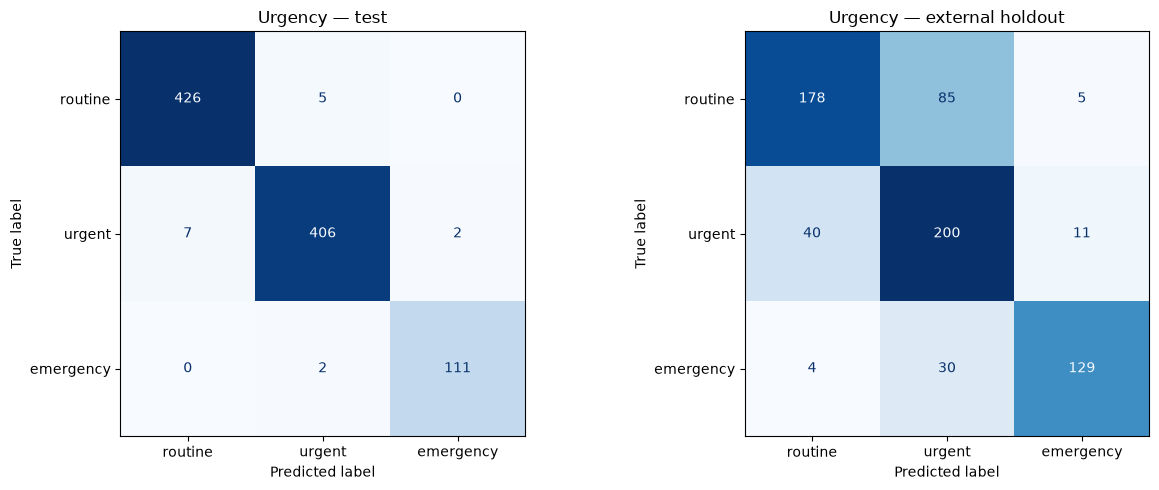

urgency on the external holdout, per class:
              precision    recall  f1-score   support

   emergency      0.890     0.791     0.838       163
     routine      0.802     0.664     0.727       268
      urgent      0.635     0.797     0.707       251

    accuracy                          0.743       682
   macro avg      0.775     0.751     0.757       682
weighted avg      0.761     0.743     0.746       682



In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels = ["routine", "urgent", "emergency"]
for ax, (frame, title) in zip(axes, [(test_df, "test"), (external, "external holdout")]):
    pred = urgency_pipeline.predict(frame["text_clean"])
    cm = confusion_matrix(frame["urgency"], pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Urgency — {title}")
plt.tight_layout()
plt.show()

print("urgency on the external holdout, per class:")
print(classification_report(external["urgency"],
                            urgency_pipeline.predict(external["text_clean"]), digits=3))

**How to read these numbers.** The right comparison is test against external holdout. Validation sits in the table only to show that it is no longer an honest estimate of anything: it was used to pick `C`, the vectorizer and the confidence threshold, so a model scoring well there was, in a small way, selected for scoring well there.

**The perfect Kazakh scores on the test split are an artefact, and should be presented as one.** The Kazakh rows were generated from a smaller phrase bank than the Russian ones, so a test row drawn from the same pool nearly always has a near-twin in training and the classifier recognises it rather than generalising. The honest Kazakh figure is the external one, several tenths lower. A score of 1.000 in a table like this is a reason to look for leakage, not a result to report.

`recall` on `emergency` is the figure to defend the system on, and it holds up considerably better across the vocabulary change than the aggregate scores do. That is the behaviour a triage system needs: a missed emergency is the one error that cannot be undone afterwards.

## 12. Does meaning beat surface form? A measured answer

Section 6b showed a dictionary ceiling, and section 7 showed that both vectorizers match *spelling*. The natural hypothesis follows: a model that represents **meaning** should not care that the holdout uses different words for the same conditions, and should therefore close the gap between 0.98 and 0.76.

This section tests that hypothesis instead of assuming it. `intfloat/multilingual-e5-small` is a sentence encoder built on XLM-R, which covers both Russian and Kazakh; each complaint becomes a 384-dimensional vector, and the same classifiers are trained on those vectors instead of on n-grams.

Embeddings are precomputed into `embeddings_e5_small.npz` so the notebook stays fast. If the file is missing the section skips itself rather than failing.

In [27]:
from pathlib import Path

EMB_FILE = Path("embeddings_e5_small.npz")
if not EMB_FILE.exists():
    print("embeddings_e5_small.npz not found — section skipped.")
    print("To regenerate: pip install sentence-transformers, then run scripts/embed_exp.py")
else:
    E = np.load(EMB_FILE)
    emb_rows = []

    clf_e = LogisticRegression(C=BEST_C, max_iter=3000, class_weight="balanced")
    clf_e.fit(E["train"], train_df["urgency"])
    for name, frame, key in [("validation", val_df, "val"),
                             ("test", test_df, "test"),
                             ("external", external, "external")]:
        p = clf_e.predict(E[key])
        emb_rows.append({"task": "urgency", "set": name,
                         "embeddings": round(f1_score(frame["urgency"], p, average="macro"), 3),
                         "emb recall emergency": round(
                             recall_score(frame["urgency"], p, labels=["emergency"],
                                          average="macro"), 3)})

    m_tr = (train_df["urgency"] != "emergency").values
    spec_e = LinearSVC(C=BEST_C_SPEC, class_weight="balanced")
    spec_e.fit(E["train"][m_tr], train_df.loc[m_tr, "specialist"])
    for name, frame, key in [("validation", val_df, "val"),
                             ("test", test_df, "test"),
                             ("external", external, "external")]:
        m = (frame["urgency"] != "emergency").values
        p = spec_e.predict(E[key][m])
        emb_rows.append({"task": "specialist", "set": name,
                         "embeddings": round(f1_score(frame.loc[m, "specialist"], p,
                                                      average="macro"), 3),
                         "emb recall emergency": float("nan")})

    emb = pd.DataFrame(emb_rows)
    print("sentence embeddings (e5-small), same splits as section 11:")
    print(emb.set_index(["task", "set"]).to_string())

sentence embeddings (e5-small), same splits as section 11:
                       embeddings  emb recall emergency
task       set                                         
urgency    validation       0.878                 0.965
           test             0.878                 0.982
           external         0.708                 0.816
specialist validation       0.915                   NaN
           test             0.910                   NaN
           external         0.755                   NaN


In [28]:
if EMB_FILE.exists():
    def _emb(task, col):
        sel = (emb["task"] == task) & (emb["set"] == "external")
        return emb.loc[sel, col].item()

    ext_row = final.loc["external holdout (other wording)"]
    comparison = pd.DataFrame([
        {"metric": "urgency f1, external",
         "char n-grams": ext_row["urgency f1_macro"],
         "embeddings": _emb("urgency", "embeddings")},
        {"metric": "recall emergency, external",
         "char n-grams": ext_row["recall emergency"],
         "embeddings": _emb("urgency", "emb recall emergency")},
        {"metric": "specialist f1, external",
         "char n-grams": ext_row["specialist f1_macro"],
         "embeddings": _emb("specialist", "embeddings")},
    ]).set_index("metric")
    print("head to head on the external holdout:")
    print(comparison.to_string())
    print()

    rows = []
    for lang in ["ru", "kk", "mixed"]:
        m = (external["lang"] == lang).values
        p = clf_e.predict(E["external"][m])
        rows.append({"lang": lang, "n": int(m.sum()),
                     "embeddings urgency f1": round(
                         f1_score(external.loc[m, "urgency"], p, average="macro"), 3)})
    print("embeddings on the external holdout, per language:")
    print(pd.DataFrame(rows).set_index("lang").to_string())

head to head on the external holdout:
                            char n-grams  embeddings
metric                                              
urgency f1, external               0.757       0.708
recall emergency, external         0.791       0.816
specialist f1, external            0.840       0.755

embeddings on the external holdout, per language:
         n  embeddings urgency f1
lang                             
ru     471                  0.633
kk     151                  0.841
mixed   60                  0.881


**The hypothesis was not confirmed, and the shape of the failure is the interesting part.** On this data the pretrained encoder loses to character n-grams almost everywhere — several points on urgency, more on specialist routing.

Two reasons, and they pull in opposite directions:

- The dataset's regularities are **lexical**, because it was generated from a phrase bank. Character n-grams are built to exploit exactly that; an encoder that abstracts away from the surface throws away the signal the data actually contains. The comparison is therefore as much a statement about the dataset as about the models.
- The encoder is **general-purpose**. It has never seen a medical complaint in Kazakh, and nothing fine-tuned it for the distinction between `routine` and `urgent`, which is a clinical judgement rather than a semantic one.

Where it does win is where the argument predicted it would: on the Kazakh portion of the external holdout, and on `recall` for emergencies on unseen wording — the two places where surface matching has the least to work with.

The practical conclusion is that embeddings are not a free upgrade here, and the honest next step is not "use a bigger model" but **fine-tuning a multilingual encoder on real complaints** — which puts the bottleneck back on data, where section 6b already put it.

## 13. The combined pipeline

In [29]:
def predict_triage(raw_text: str) -> dict:
    text_clean = clean_text(raw_text)
    entities = extract_entities_any(raw_text)

    urgency = urgency_pipeline.predict([text_clean])[0]

    # safety layer: an explicit marker raises urgency, and may never lower it
    triggered = has_red_flag(text_clean)
    if triggered and urgency != "emergency":
        urgency = "emergency"

    result = {
        "text": raw_text,
        "lang": entities.pop("lang"),
        "entities": entities,
        "urgency": urgency,
        "raised_by_rule": bool(triggered),
    }

    if urgency == "emergency":
        result.update(specialist=None, action="скорая / экстренная помощь")
        return result

    specialist = specialist_pipeline.predict([text_clean])[0]
    confident = margin_of([text_clean])[0] > CONF_THRESHOLD

    result.update(
        specialist=specialist if confident else "терапевт (уточнить)",
        action="плановая или срочная запись" if urgency == "urgent" else "обычная запись",
    )
    return result

## 14. Trying it on new complaints

None of the phrases below comes from any split of the data — they are written here to check that the whole chain behaves sensibly in all three languages.

In [30]:
test_cases = [
    "второй день болит горло, температуры нет",
    "внезапно онемела рука и перекосило лицо, речь смазанная",
    "изжога после еды почти каждый день",
    "Сәлеметсіз бе, үшінші күн тамағым ауырады, жұтынғанда ауырады",
    "басым айналады, қысымым көтерілді",
    "есінен танып қалды, дем ала алмай жатыр",
    "Сәлеметсіз бе, қызуым бар, кашель не проходит уже неделю",
    "кеудем қысылады, боль отдает в левую руку",
    "жыл сайынғы тексеруден өткім келеді",
]

for t in test_cases:
    r = predict_triage(t)
    e = r["entities"]
    facts = []
    if e["symptoms"]:
        facts.append("симптомы: " + ", ".join(e["symptoms"]))
    if e["locations"]:
        facts.append("локализация: " + ", ".join(e["locations"]))
    if e["duration_text"]:
        facts.append(f"длительность: {e['duration_text']}")
    if e["negated"]:
        facts.append("отрицает: " + ", ".join(e["negated"]))

    flag = "  [rule raised it]" if r["raised_by_rule"] else ""
    print(f"[{r['lang']:>5}] {t}")
    print(f"        urgency={r['urgency']}, specialist={r['specialist']}, "
          f"action={r['action']}{flag}")
    print(f"        extracted | {' | '.join(facts) if facts else 'no entities'}")
    print()

[   ru] второй день болит горло, температуры нет
        urgency=urgent, specialist=терапевт (уточнить), action=плановая или срочная запись
        extracted | симптомы: боль | локализация: горло | длительность: второй день | отрицает: температура

[   ru] внезапно онемела рука и перекосило лицо, речь смазанная
        urgency=emergency, specialist=None, action=скорая / экстренная помощь  [rule raised it]
        extracted | симптомы: онемение, асимметрия лица | локализация: рука, лицо, речь

[   ru] изжога после еды почти каждый день
        urgency=urgent, specialist=гастроэнтеролог, action=плановая или срочная запись
        extracted | симптомы: изжога

[   kk] Сәлеметсіз бе, үшінші күн тамағым ауырады, жұтынғанда ауырады
        urgency=urgent, specialist=ЛОР, action=плановая или срочная запись
        extracted | симптомы: боль | локализация: горло | длительность: үшінші күн

[   kk] басым айналады, қысымым көтерілді
        urgency=urgent, specialist=терапевт (уточнить), action=

**One line in that output is wrong, and it is worth leaving visible.** «изжога после еды почти каждый день» is plain Russian, and the detector labels it `mixed`. The cause is the detector design, not a bug: it classifies words one at a time, and a short complaint of ordinary words — none of which carries a Kazakh-specific letter — gives it very little orthographic evidence to work with, so a couple of uncertain words are enough to push the sentence over the `mixed` boundary.

The consequence here is harmless, because a `mixed` complaint is simply passed through both entity extractors and the Russian one still does the work. It would matter in a version that routed to a translator or to a language-specific model, and the fix is the same in either case: give the sentence-level decision a minimum amount of evidence before it is allowed to return `mixed`.

## 15. The first test on complaints we did not write

Every number so far was measured against text this project produced. That is the single largest caveat on the whole notebook, and this section removes part of it.

**RuMedTop3** is a set of real outpatient complaints in Russian, released by Sber AI Lab as part of the MedBench benchmark under Apache-2.0. Each record is the free-text complaint a patient actually presented with, labelled with a three-character ICD-10 code. 6 360 records in total, downloaded straight from the repository.

Two things have to be said before any number appears.

**It cannot test urgency at all.** The records carry a diagnosis code and nothing else. Urgency is not derivable from a diagnosis — the same condition is routine in one patient and an emergency in another — so this section tests the specialist model only.

**It covers six specialties partially.** Codes were mapped one by one rather than by chapter, because a chapter-level rule would send surgical, urological and endocrine cases to the therapist and inflate that class. What is left unmapped is not noise: it is musculoskeletal, genitourinary and endocrine complaints, which need an orthopedist, a urologist and an endocrinologist — three specialists this project does not route to.

In [31]:
import json
from pathlib import Path

# mapped code by code: a chapter-level rule would turn the therapist into a bin
ICD_TO_SPECIALIST = {
    **{c: "невролог" for c in
       ["G20", "G25", "G35", "G40", "G43", "G44", "G50", "G52", "G54", "G56",
        "G57", "G58", "G60", "G62", "G90", "G93", "G96", "G98", "I67"]},
    **{c: "кардиолог" for c in ["I10", "I11", "I20", "I25", "I48", "I49", "I50"]},
    **{c: "гастроэнтеролог" for c in
       ["K21", "K25", "K26", "K29", "K30", "K52", "K58", "K59", "K76", "K80"]},
    **{c: "дерматолог" for c in
       ["L20", "L21", "L23", "L28", "L30", "L40", "L43", "L50", "L70", "L71", "L85"]},
    **{c: "ЛОР" for c in ["J00", "J01", "J02", "J03", "J30", "J31", "J32",
                          "J34", "J35", "J37", "H65", "H66"]},
    # no pulmonologist at first contact in a polyclinic — these go to the GP
    **{c: "терапевт" for c in ["J06", "J11", "J18", "J20", "J40", "J41", "J42",
                               "J44", "J45", "J47"]},
}

REAL_DIR = Path("data_real")
real_rows = []
for part in ["train_v1.jsonl", "dev_v1.jsonl", "test_v1.jsonl"]:
    f = REAL_DIR / part
    if f.exists():
        for line in f.open(encoding="utf-8"):
            if line.strip():
                r = json.loads(line)
                r["part"] = "train" if part.startswith("train") else "devtest"
                real_rows.append(r)

if not real_rows:
    print("data_real/ not found — section skipped.")
    print("To fetch: scripts/fetch_rumedtop3.py")
else:
    real = pd.DataFrame(real_rows)
    real["specialist"] = real["code"].map(ICD_TO_SPECIALIST)
    real_mapped = real.dropna(subset=["specialist"]).reset_index(drop=True)
    real_mapped["text_clean"] = real_mapped["symptoms"].apply(clean_text)

    print(f"real complaints: {len(real)} | mapped onto our six specialties: "
          f"{len(real_mapped)} ({len(real_mapped)/len(real):.0%})")
    print()
    print(real_mapped["specialist"].value_counts().to_string())
    print()
    unmapped = real.loc[real["specialist"].isna(), "code"].str[0].value_counts()
    print("unmapped, by ICD chapter (M musculoskeletal, N genitourinary, E endocrine):")
    print(unmapped.head(6).to_string())

real complaints: 6360 | mapped onto our six specialties: 2953 (46%)

specialist
невролог           1285
кардиолог           502
терапевт            370
ЛОР                 300
гастроэнтеролог     289
дерматолог          207

unmapped, by ICD chapter (M musculoskeletal, N genitourinary, E endocrine):
code
M    1337
N     884
E     791
D     136
K      90
H      37


In [32]:
if real_rows:
    real_pred = specialist_pipeline.predict(real_mapped["text_clean"])
    print("THE SPECIALIST MODEL ON COMPLAINTS WE DID NOT WRITE")
    print(classification_report(real_mapped["specialist"], real_pred,
                                digits=3, zero_division=0))
    print()
    comparison = pd.DataFrame([
        {"tested on": "our test split", "specialist f1_macro": 0.976},
        {"tested on": "our external holdout", "specialist f1_macro": 0.840},
        {"tested on": "real complaints (RuMedTop3)",
         "specialist f1_macro": round(f1_score(real_mapped["specialist"],
                                               real_pred, average="macro"), 3)},
    ]).set_index("tested on")
    print(comparison.to_string())

THE SPECIALIST MODEL ON COMPLAINTS WE DID NOT WRITE
                 precision    recall  f1-score   support

            ЛОР      0.540     0.713     0.615       300
гастроэнтеролог      0.703     0.768     0.734       289
     дерматолог      0.735     0.802     0.767       207
      кардиолог      0.576     0.566     0.571       502
       невролог      0.817     0.637     0.716      1285
       терапевт      0.377     0.530     0.440       370

       accuracy                          0.644      2953
      macro avg      0.625     0.669     0.641      2953
   weighted avg      0.676     0.644     0.652      2953


                             specialist f1_macro
tested on                                       
our test split                             0.976
our external holdout                       0.840
real complaints (RuMedTop3)                0.641


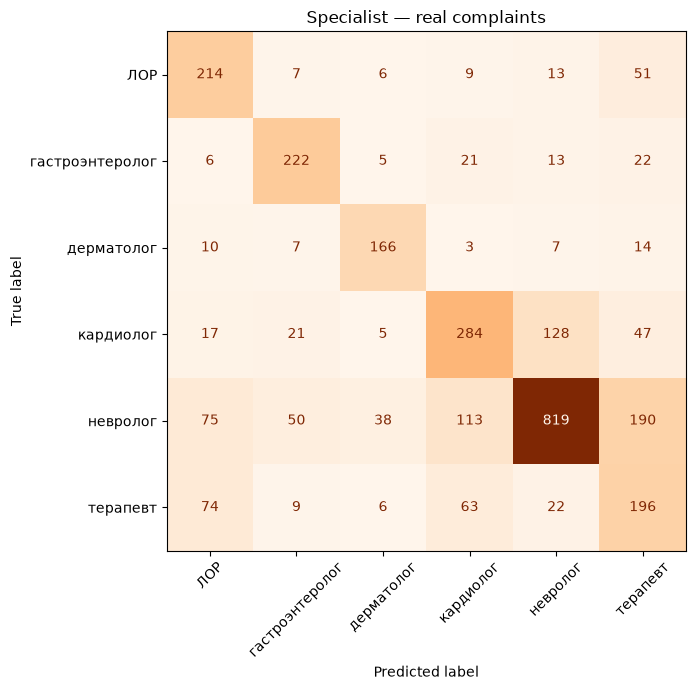

In [33]:
if real_rows:
    labels_r = sorted(real_mapped["specialist"].unique())
    cm_r = confusion_matrix(real_mapped["specialist"], real_pred, labels=labels_r)
    fig, ax = plt.subplots(figsize=(7.5, 7))
    ConfusionMatrixDisplay(cm_r, display_labels=labels_r).plot(
        cmap="Oranges", ax=ax, xticks_rotation=45, colorbar=False)
    plt.title("Specialist — real complaints")
    plt.tight_layout()
    plt.show()

**Reading it.** The score on text written by other people is well below the score on text written by us, and that gap is the most honest thing in this notebook. It is also the expected direction: our training complaints are what a patient types into a booking form, while these are intake notes written in clinical shorthand — `с иррад в кисть`, `по ВАШ 6-7 баллов`, `t\\б сустава`. The vocabulary differs, and so does the genre.

The confusion matrix shows where it breaks, and the errors are clinically sensible rather than random:

- **Cardiology and neurology trade cases in both directions.** Chest pain radiating into an arm, dizziness, numbness — these genuinely belong to either, and the text alone often does not settle it.
- **The therapist class is the weakest**, as it has been on every set we have measured. It is the class with no symptom profile of its own, so it absorbs whatever the others reject.
- **Dermatology holds up best.** Skin complaints use a vocabulary nothing else shares.

In [34]:
if real_rows:
    sample_real = real_mapped.sample(min(800, len(real_mapped)), random_state=3)
    ents_real = [extract_entities_any(t) for t in sample_real["symptoms"]]
    n = len(sample_real)

    print(f"the NER layer on real clinical text ({n} complaints)")
    print(f"  at least one entity : {sum(1 for e in ents_real if e['symptoms'] or e['locations'])/n:.1%}")
    print(f"  a symptom           : {sum(1 for e in ents_real if e['symptoms'])/n:.1%}")
    print(f"  a body site         : {sum(1 for e in ents_real if e['locations'])/n:.1%}")
    print(f"  a duration          : {sum(1 for e in ents_real if e['duration_text'])/n:.1%}")
    print()

    # how often a duration is stated at all, so the figure above can be read
    import re as _re
    STATES_DURATION = _re.compile(
        r"\d+\s*-?\s*[а-я]{0,2}\s*(год|лет|мес|нед|дн|ден|сут|час|мин)"
        r"|(перв|втор|трет|четверт|пят)\w*\s*(год|мес|нед|дн|сут)"
        r"|(вчера|сегодня|давно|детств|много лет|с утра)", _re.IGNORECASE)
    devtest = real_mapped[real_mapped["part"] == "devtest"].head(1200)
    stated = [bool(STATES_DURATION.search(t)) for t in devtest["symptoms"]]
    found = [bool(extract_entities_any(t)["duration_text"]) for t in devtest["symptoms"]]
    hit = sum(1 for s, f in zip(stated, found) if s and f)
    print(f"of {len(devtest)} unseen real complaints, {sum(stated)/len(stated):.0%} state a "
          f"duration at all; of those we catch {hit/max(sum(stated),1):.0%}")

the NER layer on real clinical text (800 complaints)
  at least one entity : 92.1%
  a symptom           : 84.9%
  a body site         : 69.0%
  a duration          : 18.1%



of 816 unseen real complaints, 19% state a duration at all; of those we catch 83%


**Two results worth separating.** Coverage on real text is *higher* than on our own holdout, and that is not the layer improving. Real intake notes are symptom-dense — a clinician lists everything — while our synthetic complaints are short and a fair share of them are administrative requests with no symptom in them at all. Coverage went up because there was more to find. This is the same lesson as section 6b from the other direction: coverage tracks how much is in the text, not how well the layer reads it.

The duration figure needed the second measurement before it could be read at all. Taken alone it looks like a failure. Checked against how often a duration is *stated*, most of the shortfall is the data: a clinical note records findings, not calendars. Of the complaints that do state one, the layer now catches the large majority — after a fix found on the training portion of this corpus and reported here on the part never used for it.

## 16. Summary and limitations

**What the system does.** A complaint in Russian, Kazakh or both goes in; out come the detected language, the entities the decision rests on, an urgency level, and either a specialist or an ambulance. It does not diagnose.

### The number that matters

Specialist routing, measured on three sets that were earned very differently:

| tested on | who wrote it | f1_macro |
|---|---|---|
| our test split | us | 0.976 |
| our external holdout | us, in deliberately different words | 0.840 |
| **real complaints (RuMedTop3)** | **actual patients and clinicians** | **0.641** |

Each step down is a weaker assumption being removed. The last one is the first measurement in this project against text nobody here wrote, and 0.641 is the figure the project should be judged on.

For urgency the honest figure remains 0.757 on our external holdout, with `recall` on emergencies at 0.791. Real data could not test urgency: RuMedTop3 records carry a diagnosis code and nothing about how urgently the patient needed to be seen.

### Three rounds of work

**Round one — language.** Kazakh and code-switched complaints (4 995 → 6 387 rows), a learned word-level language detector, a Kazakh entity layer on stems and suffixes, Kazakh red-flag patterns. Three bugs surfaced that had all failed silently: a character class that deleted every Kazakh-specific letter, labels taken from one half of a two-fragment row, and a name-detector that erased symptoms from the start of a sentence.

**Round two — measurement.** NER quality had been reported as *coverage* — the share of complaints with at least one entity found, 75-86%. A hand-annotated gold standard replaced it with the quantity it was standing in for: symptom recall **0.536** at precision 0.949. Three things followed: the dictionary has a ceiling that mining the training split cannot pass (0 of 15 failing words occur there; 52% of holdout vocabulary never appears in training); the red-flag rules, rewritten as stem regexes, went from 0.301 to 0.717 recall at a deliberate cost in precision; and sentence embeddings were tested against character n-grams and **lost** — 0.708 against 0.757 — because the data's regularities are lexical by construction.

**Round three — real data.** 6 360 real outpatient complaints from RuMedTop3 (Apache-2.0), mapped code by code onto six specialties, 46% of them covered. Two findings beyond the headline number:

- **Coverage rose on real text** (92% against 76% on our holdout) while the layer did not improve. Clinical notes are symptom-dense; our synthetic complaints are short and often administrative. Coverage tracks how much is in the text, which is the same lesson as round two from the other side.
- **The duration figure needed a second measurement to be readable.** 18% looked like failure; only 19% of real complaints state a duration at all, and of those the layer catches 83% — after a fix found on the training portion of the corpus and reported on the part never used for it.

### Limitations

- The Kazakh half of the dataset is still entirely synthetic and **unreviewed by a native speaker or a clinician**. No public Kazakh clinical corpus exists to validate against — only a gated medical *speech* dataset.
- Urgency has never been tested on real data, and no public Russian or Kazakh corpus carries urgency labels.
- The real-data check covers 46% of RuMedTop3. The rest is musculoskeletal, genitourinary and endocrine — three specialties this project does not route to.
- The gold standard is 60 complaints annotated by one person, the project's own author. A second annotator and inter-annotator agreement are needed before the NER figures carry real weight.
- The system does no **assertion detection**: `хочу проверить давление` is a request, not a reported symptom.
- The red-flag list is not a medical triage protocol and needs review by a physician and alignment with the clinical protocols of the Ministry of Health of Kazakhstan.
- Psychiatric crises and suicidal statements are not covered by the six specialties.

### What comes next

1. **Urgency on real data** — the remaining untested half of the system. No public corpus carries the labels, so this needs either a physician annotating a sample of RuMedTop3, or a prospective collection with consent.
2. **A second annotator** on the gold standard, with agreement reported.
3. **An external medical lexicon** instead of a hand-written dictionary — the only route past the section 6c ceiling that keeps the lexical approach.
4. **Fine-tune a multilingual encoder** on complaint text. Section 12 shows the off-the-shelf version is not enough; it does not show embeddings cannot work.
5. **Assertion detection**, so a mentioned symptom and a reported one stop being the same thing.
6. **Native-speaker and clinical review** of the Kazakh corpus and the red-flag list.